# Lift diagnostics baseline: data, metrics, and what they mean for Bézier-RFM

**Who this is for:** you have read `robomimic_lift_dataset.ipynb` (Parts 1 to 4), so you know what a robosuite state is, what `reset_to` does, and how delta and absolute actions differ.

**What you will be able to do at the end:**
- Say which trajectory in the dataset is the Bézier fitting target, and how it relates to what the robot actually did.
- Say what every recorded metric measures, why it is recorded, and what a normal value is.
- Read the 200-demonstration baseline and its failures.
- Run a new command sequence through the same evaluation, and compare it with the baseline.
- Make the open decisions for Bézier fitting and RFM training, each backed by evidence from this notebook.

**Outline**

- **Part 1. One demonstration:** the three trajectories, the alignment rule, and poses in SO(3) × R³.
- **Part 2. The trace:** how each trajectory is recorded, field by field.
- **Part 3. The metrics:** command fidelity, tracking error, achieved vs recording, task outcome, phases and contact.
- **Part 4. The 200-demonstration baseline:** distributions, failures, and what the validation proved.
- **Part 5. Properties of the fitting target:** what the commanded sequences look like before any fit.
- **Part 6. Evaluating a candidate and deciding next steps.**

Each part ends with an exercise. Solve it before you go to the next part.

**Before you run:** most cells read saved files in `docs/diagnostics/`. That folder is not in git. On a fresh copy of the repository, make the files first:

```
uv run python scripts/build_diagnostic_traces.py --demos all
uv run python scripts/validate_diagnostics.py
uv run python scripts/diagnostics_report.py --figures demo_0 demo_2 demo_55 demo_91 demo_115 demo_177
```

In [1]:
import json
from pathlib import Path

import h5py
import matplotlib.pyplot as plt
import numpy as np
from scipy.spatial.transform import Rotation

from bezier_rfm.datasets.robomimic import demo_keys
from bezier_rfm.eval.lift_diagnostics import CONTROL_DT, geodesic, read_trace

ROOT = Path.cwd() if (Path.cwd() / "pyproject.toml").exists() else Path.cwd().parent
SOURCE_PATH = ROOT / "data/robomimic/datasets/lift/ph/low_dim_v15.hdf5"
ABS_PATH = ROOT / "data/robomimic/datasets/lift/ph/low_dim_abs.hdf5"
TRACES_PATH = ROOT / "docs/diagnostics/baseline_traces.hdf5"

with h5py.File(TRACES_PATH, "r") as f:
    meta = read_trace(f["meta"])[1]
    DEMOS = demo_keys({k: None for k in f if k != "meta"})


def load_pair(name):
    '''Load the recorded and replay traces of one demonstration.

    Args:
        name (str): Demonstration name.

    Returns:
        tuple: Recorded trace (dict) and replay trace (dict).
    '''
    with h5py.File(TRACES_PATH, "r") as f:
        return read_trace(f[f"{name}/recorded"])[0], read_trace(f[f"{name}/replay_absolute"])[0]


print(f"{len(DEMOS)} demonstrations in the traces file")
print(f"control frequency {meta['control_freq']} Hz, physics timestep {meta['model_timestep']} s, {meta['substeps']} physics steps per action")

200 demonstrations in the traces file
control frequency 20.0 Hz, physics timestep 0.002 s, 25 physics steps per action


---
# Part 1. One demonstration

## 1.1 What a demonstration contains

A person drove the robot with a 3D mouse, and the dataset saved what happened. Each demonstration has:

| Array | Rows | Meaning |
| --- | --- | --- |
| `states` | N | the full simulator state at each control step: time, joint angles, cube pose, and all speeds (32 numbers) |
| `actions` | N | the command given at each control step (7 numbers) |
| `obs` | N | derived values, such as the gripper position, read from each state |

The robot is controlled at **20 Hz**. One action is held for 0.05 s. During that time, the physics simulator takes 25 small steps of 0.002 s.

We use two files. Both have the same states. They differ only in the actions:
- `low_dim_v15.hdf5`: the original **delta** actions ("move 2 cm to the left").
- `low_dim_abs.hdf5`: our converted **absolute** actions ("go to this pose").

The absolute actions are what a Bézier curve will produce later, so this notebook uses them.

demo_0 states:  (59, 32)
demo_0 actions: (59, 7) (x, y, z, rotation vector x, y, z, gripper)


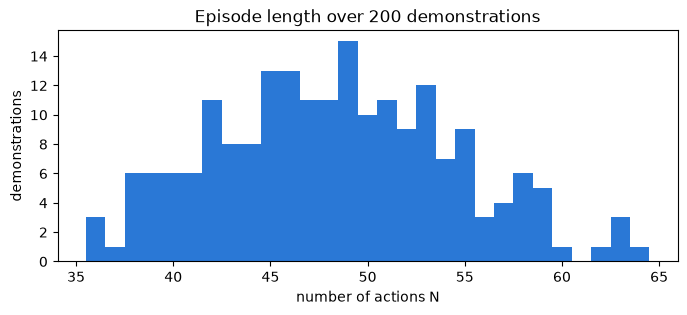

N: min 36, median 48, max 64, which is 1.80 s to 3.20 s


In [2]:
with h5py.File(SOURCE_PATH, "r") as src, h5py.File(ABS_PATH, "r") as ab:
    d0 = src["data/demo_0"]
    print("demo_0 states: ", d0["states"].shape)
    print("demo_0 actions:", ab["data/demo_0/actions"].shape, "(x, y, z, rotation vector x, y, z, gripper)")
    lengths = np.array([src[f"data/{k}/actions"].shape[0] for k in demo_keys(src["data"])])

fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(lengths, bins=np.arange(lengths.min(), lengths.max() + 2) - 0.5, color="#2a78d6")
ax.set(xlabel="number of actions N", ylabel="demonstrations", title="Episode length over 200 demonstrations")
plt.show()
print(f"N: min {lengths.min()}, median {np.median(lengths):.0f}, max {lengths.max()}, which is {lengths.min() * CONTROL_DT:.2f} s to {lengths.max() * CONTROL_DT:.2f} s")

Each demonstration is short: about 2 to 3 seconds. Lengths differ by almost a factor of two. Keep this in mind for Part 5, where the length of a Bézier segment must be chosen.

## 1.2 Three trajectories and the alignment rule

For every demonstration we have three trajectories of the **grip site**, the point between the two fingertips:

| Symbol | Name | Where it comes from |
| --- | --- | --- |
| $p^{cmd}_t,\ R^{cmd}_t$ | **commanded** | the absolute action $t$: where the controller is told to go |
| $p^{rec}_k,\ R^{rec}_k$ | **recorded achieved** | the stored state $k$: where the robot really was in the recording |
| $p^{rep}_k,\ R^{rep}_k$ | **replayed achieved** | our simulator run of the absolute actions from the first state |

Later, a fourth trajectory joins them: the achieved motion when the commands come from a fitted Bézier curve.

**The alignment rule.** Commands are indexed by action $t$, and achieved poses by state $k$. They are linked like this:

```
state:    k=0          k=1          k=2          k=3
time:     0.00 s       0.05 s       0.10 s       0.15 s
          |--action 0--|--action 1--|--action 2--|
```

Action $t$ starts at state $t$ and ends at state $t+1$. So the command $t$ is judged by the achieved pose at state $t+1$. This rule is used in every metric and every plot in this notebook.

A demonstration with $N$ actions has $N+1$ moments. The recording stores only $N$ states, so it has no pose after the final action. The replay has all $N+1$.

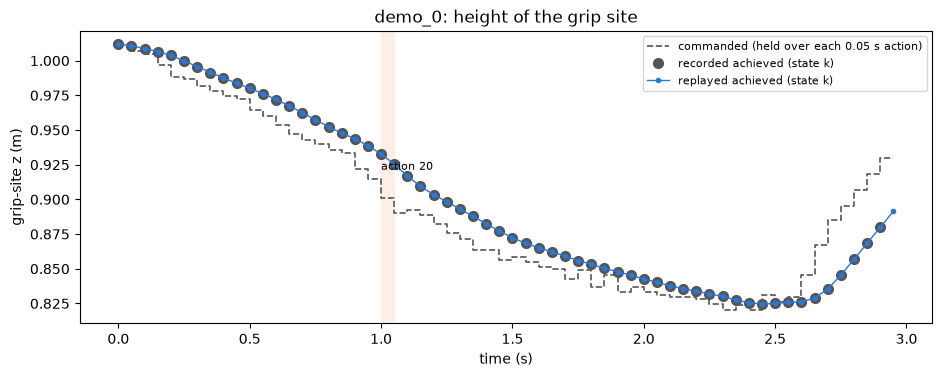

action 20 runs from 1.00 s to 1.05 s
  command z:                        0.9013 m
  recorded z at the start (k = 20):  0.9328 m
  recorded z at the end (k = 21):    0.9255 m
  replayed z at the end (k = 21):    0.9255 m


In [3]:
recorded, replay = load_pair("demo_0")
t_state = CONTROL_DT * np.arange(len(replay["valid"]))

fig, ax = plt.subplots(figsize=(11, 3.8))
ax.step(np.r_[recorded["t_start"], recorded["t_end"][-1]], np.r_[recorded["cmd_pos"][:, 2], recorded["cmd_pos"][-1, 2]], where="post", color="#555555", ls="--", lw=1.2, label="commanded (held over each 0.05 s action)")
ok = recorded["valid"]
ax.plot(t_state[ok], recorded["ach_pos"][ok, 2], "o", color="#555555", ms=7, label="recorded achieved (state k)")
ax.plot(t_state, replay["ach_pos"][:, 2], "o-", color="#2a78d6", ms=3, lw=1, label="replayed achieved (state k)")
t = 20
ax.axvspan(recorded["t_start"][t], recorded["t_end"][t], color="#fdeee6")
ax.annotate(f"action {t}", (recorded["t_start"][t], recorded["cmd_pos"][t, 2]), xytext=(0, 20), textcoords="offset points", fontsize=8)
ax.set(xlabel="time (s)", ylabel="grip-site z (m)", title="demo_0: height of the grip site")
ax.legend(fontsize=8)
plt.show()

print(f"action {t} runs from {recorded['t_start'][t]:.2f} s to {recorded['t_end'][t]:.2f} s")
print(f"  command z:                        {recorded['cmd_pos'][t, 2]:.4f} m")
print(f"  recorded z at the start (k = {t}):  {recorded['ach_pos'][t, 2]:.4f} m")
print(f"  recorded z at the end (k = {t + 1}):    {recorded['ach_pos'][t + 1, 2]:.4f} m")
print(f"  replayed z at the end (k = {t + 1}):    {replay['ach_pos'][t + 1, 2]:.4f} m")

**What the plot shows:**
- The dashed command is always **below** the achieved height while the gripper moves down. The command leads, and the robot follows. Part 3 measures this lag.
- The blue replay dots sit on the grey recorded dots. Running the absolute actions reproduces the recording closely. Part 3 measures how closely.
- The commanded steps are jagged, but the achieved path is smooth. The commands come from a person's hand, and the controller smooths them. This matters for the fitting target (Part 5).

## 1.3 Poses in SO(3) × R³

A pose has two parts:
- a **position** $p \in \mathbb{R}^3$, three numbers in metres;
- an **orientation** $R \in SO(3)$, a 3 × 3 rotation matrix. It has 9 numbers, but only 3 degrees of freedom.

The absolute actions store the orientation as a **rotation vector**: an axis times an angle, three numbers. This is compact, but it has a problem. Near an angle of π, two rotation vectors that point in almost opposite directions describe almost the same rotation. So the three stored numbers can jump by about 2π while the real rotation barely changes.

To measure how far apart two orientations are, we use the **geodesic distance**:

$$
d(R_a, R_b) = \left\| \operatorname{Log}\left(R_a^\top R_b\right) \right\|
$$

$R_a^\top R_b$ is the rotation that takes $R_a$ to $R_b$. $\operatorname{Log}$ turns it into a rotation vector, and its length is the smallest angle of that rotation. This distance does not depend on how the rotation is written down, so it has no jumps. In code, it is `geodesic(rot_a, rot_b)`.

The next cell shows `demo_2`, where the stored numbers jump four times.

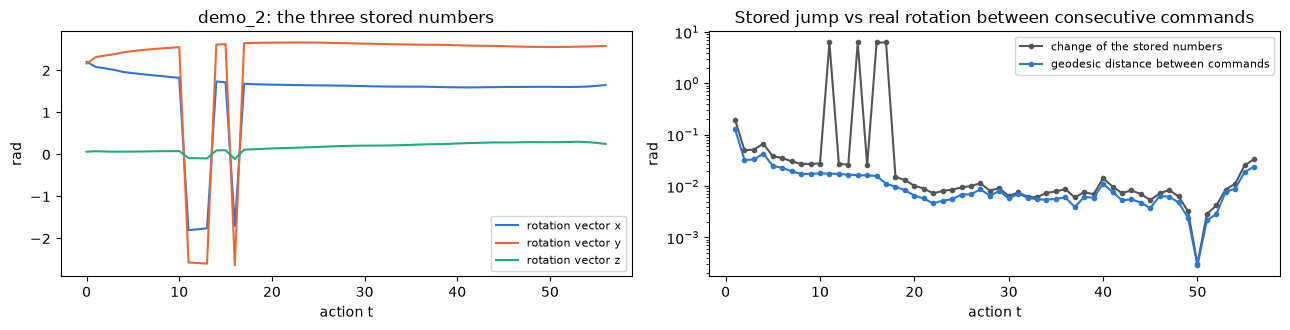

jumps at t = [11, 14, 16, 17]
stored change at the jumps (rad):     [6.282 6.28  6.281 6.281]
geodesic distance at the jumps (rad): [0.017 0.016 0.016 0.011]


In [4]:
with h5py.File(ABS_PATH, "r") as ab:
    rotvec = ab["data/demo_2/actions"][:, 3:6]
rec2, _ = load_pair("demo_2")
stored_change = np.linalg.norm(np.diff(rotvec, axis=0), axis=1)
true_change = geodesic(rec2["cmd_rot"][:-1], rec2["cmd_rot"][1:])

fig, axes = plt.subplots(1, 2, figsize=(13, 3.4))
for i, (axis_name, color) in enumerate(zip("xyz", ("#2a78d6", "#eb6834", "#1baf7a"))):
    axes[0].plot(rotvec[:, i], color=color, label=f"rotation vector {axis_name}")
axes[0].set(xlabel="action t", ylabel="rad", title="demo_2: the three stored numbers")
axes[0].legend(fontsize=8)
axes[1].semilogy(np.arange(1, len(rotvec)), stored_change, "o-", ms=3, color="#555555", label="change of the stored numbers")
axes[1].semilogy(np.arange(1, len(rotvec)), true_change, "o-", ms=3, color="#2a78d6", label="geodesic distance between commands")
axes[1].set(xlabel="action t", ylabel="rad", title="Stored jump vs real rotation between consecutive commands")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

jumps = np.flatnonzero(stored_change > 1.0) + 1
print("jumps at t =", jumps.tolist())
print("stored change at the jumps (rad):    ", np.round(stored_change[jumps - 1], 3))
print("geodesic distance at the jumps (rad):", np.round(true_change[jumps - 1], 3))

At each jump, the stored numbers change by almost 2π (6.28 rad), but the robot's commanded orientation turns by only about 1°. So:

- **Never** average, subtract, or fit rotation vectors directly. A fit through the stored numbers would see a jump that does not exist.
- Compare orientations only with the geodesic distance.
- The traces store orientations as rotation matrices. Rotation vectors are formed only at the last moment, when a command goes to the controller.

**Plotting orientation.** A plot needs three numbers per orientation. We plot the rotation vector of $R_0^\top R$, where $R_0$ is the recorded orientation at $t = 0$. This is the rotation **relative to the start**. It is safe as long as these angles stay well below π. The next cell checks that across all 200 demonstrations.

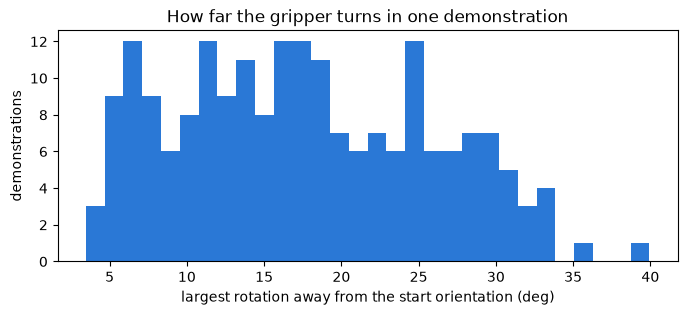

largest turn per demonstration: median 17.2 deg, max 39.9 deg


In [5]:
max_turn = []
with h5py.File(TRACES_PATH, "r") as f:
    for name in DEMOS:
        rot = f[f"{name}/recorded/ach_rot"][:]
        valid = f[f"{name}/recorded/valid"][:]
        max_turn.append(geodesic(np.repeat(rot[:1], valid.sum(), axis=0), rot[valid]).max())
max_turn = np.degrees(max_turn)

fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(max_turn, bins=30, color="#2a78d6")
ax.set(xlabel="largest rotation away from the start orientation (deg)", ylabel="demonstrations", title="How far the gripper turns in one demonstration")
plt.show()
print(f"largest turn per demonstration: median {np.median(max_turn):.1f} deg, max {max_turn.max():.1f} deg")

The gripper never turns more than about 40° away from its start orientation. So the plot of $R_0^\top R$ has no jumps, and the orientations of one demonstration stay in a small region of SO(3). This fact will matter again in Part 5.

## Part 1 summary

- A demonstration has $N$ actions (36 to 64) at 20 Hz. Each action is held for 0.05 s.
- There are three trajectories: **commanded**, **recorded achieved**, and **replayed achieved**.
- **Alignment rule:** action $t$ runs from state $t$ to state $t+1$, and is judged at state $t+1$.
- The command leads the achieved pose, and the commands are more jagged than the achieved path.
- Orientations are compared with the geodesic distance, never as rotation vectors. Stored rotation vectors can jump by about 2π with no real rotation.
- In one demonstration, the gripper turns at most about 40° from its start.

**Common mistake:** comparing command $t$ with the achieved pose at state $t$, the **start** of its interval. That pose existed before the command was given, so it cannot show how well the command was followed.

## Exercise 1

Use `demo_91`.

1. Load its traces with `load_pair`.
2. Using the alignment rule, compute for every action $t$ the **position** distance between the command and the recorded achieved pose at the end of its interval. Skip actions with no recorded pose at the end.
3. Compute the **orientation** distance in the same way, with `geodesic`.
4. Report the action $t$ with the largest position distance, its value in mm, and the time in seconds at which its interval starts.
5. Do the same for the orientation distance, in degrees.

Write your answer in the next cell.

In [6]:
# Your answer for Exercise 1.
rec91, _ = load_pair("demo_91")
t_state = CONTROL_DT * np.arange(len(rec91["valid"]))
dist_err = np.linalg.norm(rec91["cmd_pos"][:-1] - rec91["ach_pos"][1:-1], axis=1)
rot_err = geodesic(rec91["cmd_rot"][:-1], rec91["ach_rot"][1:-1])

max_dist_err_idx = np.argmax(dist_err)
print(f"Largest position distance between commanded and recorded achieved pose = {np.max(dist_err) * 1000:.2f} mm, interval starts at {t_state[max_dist_err_idx]} s and for a commanded position action value of {rec91["cmd_pos"][max_dist_err_idx]}.")
max_rot_err_idx = np.argmax(rot_err)
print(f"Largest orientation distance between commanded and recorded achieved pose = {np.degrees(np.max(rot_err)):.2f} deg, interval starts at {t_state[max_rot_err_idx]} s.")


Largest position distance between commanded and recorded achieved pose = 46.09 mm, interval starts at 0.25 s and for a commanded position action value of [-0.03847064 -0.02683798  0.93668039].
Largest orientation distance between commanded and recorded achieved pose = 5.33 deg, interval starts at 0.4 s.


---
# Part 2. The trace

Part 1 used the traces without saying how they were made. Part 2 explains the format: what each field holds, where its value comes from, and why it is recorded.

**Why one format.** The recording, the replay, and later every Bézier candidate are stored in the **same** format, called a **trace**. So one set of metric and plot functions works for all of them, and a Bézier result can be compared with the baseline without any conversion.

## 2.1 The fields

A trace of a demonstration with $N$ actions has two kinds of rows:

**Per action** ($N$ rows, index $t$):

| Field | Shape | Unit | Meaning | Why it is recorded |
| --- | --- | --- | --- | --- |
| `t_start`, `t_end` | (N,) | s | start and end time of action $t$: $0.05t$ and $0.05(t+1)$ | makes the alignment rule explicit |
| `cmd_pos` | (N, 3) | m | commanded grip-site position | the fitting target |
| `cmd_rot` | (N, 3, 3) | – | commanded grip-site orientation | the fitting target |
| `gripper_cmd` | (N,) | – | gripper command, −1 open, +1 close | the grasp behaviour |
| `goal_pos`, `goal_rot` | (N, 3), (N, 3, 3) | m, – | the goal the controller really used (replay only) | separates input problems from tracking problems |

**Per state** ($N+1$ rows, index $k$):

| Field | Shape | Unit | Meaning | Why it is recorded |
| --- | --- | --- | --- | --- |
| `valid` | (N+1,) | – | whether this state exists | the recording has no state $N$ |
| `sim_time` | (N+1,) | s | simulator clock | checks the 0.05 s spacing |
| `state` | (N+1, 32) | mixed | full simulator state | lets any state be restored later |
| `ach_pos`, `ach_rot` | (N+1, 3), (N+1, 3, 3) | m, – | achieved grip-site pose | how the robot really moved |
| `ach_linvel`, `ach_angvel` | (N+1, 3) | m/s, rad/s | grip-site velocity in the world frame | motion and smoothness |
| `finger_q` | (N+1, 2) | m | positions of the two fingers | whether the grasp closes on the cube |
| `cube_pos`, `cube_rot` | (N+1, 3), (N+1, 3, 3) | m, – | cube pose | what happens to the object |
| `cube_height` | (N+1,) | m | cube centre above the table top | the lift rule |
| `gripper_to_cube` | (N+1,) | m | distance from grip site to cube centre | approach progress, and slipping |
| `contact` | (N+1,) | – | whether a finger touches the cube | marks contact-sensitive steps |
| `success` | (N+1,) | – | whether the cube meets the lift rule | task outcome |

Rows that do not exist hold NaN (numbers) or False (flags), and `valid` is False there.

In [7]:
recorded, replay = load_pair("demo_0")
n = len(recorded["cmd_pos"])
print(f"demo_0: N = {n} actions\n")
print(f"{'field':16s}{'recorded':>16s}{'replay':>16s}")
for name in recorded:
    print(f"{name:16s}{str(recorded[name].shape):>16s}{str(replay[name].shape):>16s}")

print(f"\nvalid states: recorded {recorded['valid'].sum()} of {n + 1}, replay {replay['valid'].sum()} of {n + 1}")
print("recorded ach_pos at state N:", recorded["ach_pos"][n])
print("recorded goal_pos is all NaN:", bool(np.isnan(recorded["goal_pos"]).all()))

demo_0: N = 59 actions

field                   recorded          replay
ach_angvel               (60, 3)         (60, 3)
ach_linvel               (60, 3)         (60, 3)
ach_pos                  (60, 3)         (60, 3)
ach_rot               (60, 3, 3)      (60, 3, 3)
cmd_pos                  (59, 3)         (59, 3)
cmd_rot               (59, 3, 3)      (59, 3, 3)
contact                    (60,)           (60,)
cube_height                (60,)           (60,)
cube_pos                 (60, 3)         (60, 3)
cube_rot              (60, 3, 3)      (60, 3, 3)
finger_q                 (60, 2)         (60, 2)
goal_pos                 (59, 3)         (59, 3)
goal_rot              (59, 3, 3)      (59, 3, 3)
gripper_cmd                (59,)           (59,)
gripper_to_cube            (60,)           (60,)
sim_time                   (60,)           (60,)
state                   (60, 32)        (60, 32)
success                    (60,)           (60,)
t_end                      (59,)           (5

Two kinds of row are deliberately empty:
- The recording has no state $N$, so that row is NaN and `valid[N]` is False.
- The recording has no controller goals, because we never ran a controller to make it. Its `goal_pos` and `goal_rot` are all NaN.

Always use `valid` or a NaN-aware function (`np.nanmax`, `np.nanmedian`) on per-state fields. Exercise 1 showed why.

## 2.2 Where each value comes from

One function, `read_state(env)`, reads every per-state field from the simulator. Four details matter.

**1. It calls `sim.forward()` first.** After a physics step, MuJoCo's stored poses describe the joint angles from **before** the last step. `forward()` recomputes them from the current joint angles. Without it, every pose would lag by one physics step (Step 1 of the earlier notebook).

**2. It uses the grip site, not the hand body.** The dataset has two orientations: `robot0_eef_quat_site` (the grip site, used by the controller) and `robot0_eef_quat` (the hand body). The next cell shows that they differ by a constant 90°. A Bézier curve must describe the same frame that the controller uses, so we use the grip site.

In [8]:
with h5py.File(SOURCE_PATH, "r") as src:
    obs0 = src["data/demo_0/obs"]
    site_rot = Rotation.from_quat(obs0["robot0_eef_quat_site"][:]).as_matrix()
    body_rot = Rotation.from_quat(obs0["robot0_eef_quat"][:]).as_matrix()
    stored_pos = obs0["robot0_eef_pos"][:]
    site_quat_dtype = obs0["robot0_eef_quat_site"].dtype

print("trace vs obs site position:      max", f"{np.linalg.norm(recorded['ach_pos'][:n] - stored_pos, axis=1).max():.1e} m")
print("trace vs obs site orientation:   max", f"{geodesic(recorded['ach_rot'][:n], site_rot).max():.1e} rad")
print("trace vs obs body orientation:   median", f"{np.degrees(np.median(geodesic(recorded['ach_rot'][:n], body_rot))):.1f} deg")
print("dtype of robot0_eef_quat_site:  ", site_quat_dtype)

trace vs obs site position:      max 4.5e-16 m
trace vs obs site orientation:   max 4.3e-07 rad
trace vs obs body orientation:   median 90.0 deg
dtype of robot0_eef_quat_site:   float32


The trace matches the stored site position to rounding level. The site orientation matches to about 4e-7 rad, not 1e-16. The reason is that the dataset stores this quaternion in **float32**, which keeps only about 7 significant digits. The trace keeps full float64 precision.

**3. Velocity is read directly.** `mujoco.mj_objectVelocity` gives the grip site's linear and angular velocity in the world frame. The validation checked that it equals the Jacobian times the joint speeds at every stored state, to within 3.3e-16. It is the velocity at one instant. It is not an average over the 0.05 s interval.

**4. Cube height is measured from the table top.** Lift counts the cube as lifted when its centre is more than 4 cm above the table top. We use the same reference. A height measured from the cube's first position would be misleading, as the next cell shows.

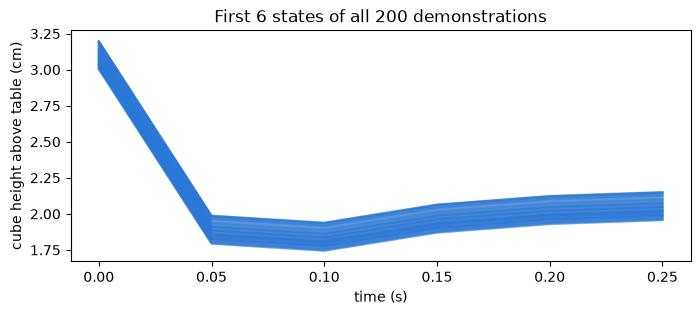

height at state 0: 3.00 to 3.20 cm
drop from state 0 to state 5: 1.05 to 1.05 cm


In [9]:
with h5py.File(TRACES_PATH, "r") as f:
    first_heights = np.array([f[f"{name}/recorded/cube_height"][:6] for name in DEMOS]) * 100

fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(CONTROL_DT * np.arange(6), first_heights.T, color="#2a78d6", alpha=0.15)
ax.set(xlabel="time (s)", ylabel="cube height above table (cm)", title="First 6 states of all 200 demonstrations")
plt.show()
drop = first_heights[:, 0] - first_heights[:, 5]
print(f"height at state 0: {first_heights[:, 0].min():.2f} to {first_heights[:, 0].max():.2f} cm")
print(f"drop from state 0 to state 5: {drop.min():.2f} to {drop.max():.2f} cm")

The cube starts about 1 cm above its resting height in every demonstration, and falls onto the table in the first 0.1 s. Its resting height is about 2.1 cm, because the 4 cm lift rule is measured at the cube's **centre**. So "lifted" means the centre has risen about 2 cm above where it rests.

## 2.3 How the recorded and replay traces are made

The two traces are built in different ways:

| | Recorded trace (`record_trace`) | Replay trace (`evaluate_commands`) |
| --- | --- | --- |
| States | restores **each** stored state, and reads it | restores state 0 **once**, then runs the actions |
| Physics | none, it only reads | 25 physics steps per action |
| Commands | the stored absolute actions | the same actions, sent to the controller |
| Controller goals | none | read after every action |
| First step | – | **refreshed**: the controller reads the true pose first |

**Why refreshed.** After a model is loaded, the controller still holds an old pose. Unless it is refreshed, it uses that pose for its first step. At deployment, after `env.reset()`, the controller's pose is already correct. So the refreshed start is the one that matches deployment.

**Why the stored actions are passed unchanged.** A Bézier curve will give rotation matrices, and `commands_to_actions` turns them into rotation vectors. That round trip changes the numbers by up to about 1e-15, and Part 3 of the earlier notebook showed that contact can magnify differences that small. So the baseline sends the stored actions directly, and is exactly reproducible.

The next cell runs the replay of `demo_0` live, and compares it with the saved trace.

In [10]:
from bezier_rfm.datasets.robomimic import make_env
from bezier_rfm.eval.lift_diagnostics import commands_to_actions, evaluate_commands

with h5py.File(SOURCE_PATH, "r") as src, h5py.File(ABS_PATH, "r") as ab:
    env = make_env(json.loads(meta["env_args"]), src["data/demo_0/obs"].keys())
    actions = ab["data/demo_0/actions"][:]
    live = evaluate_commands(env, src["data/demo_0"], actions, start="refreshed")

same = all(np.array_equal(live[k], replay[k], equal_nan=True) for k in replay)
print("live replay identical to the saved trace:", same)

round_trip = commands_to_actions(live["cmd_pos"], live["cmd_rot"], live["gripper_cmd"])
print(f"rotation vector change after matrix round trip: max {np.abs(round_trip[:, 3:6] - actions[:, 3:6]).max():.1e} rad")

[robosuite WARNING] No private macro file found! (macros.py:53)


[robosuite WARNING] It is recommended to use a private macro file (macros.py:54)


[robosuite WARNING] To setup, run: python /home/abbas/Projects/bezier-rfm/.venv/lib/python3.12/site-packages/robosuite/scripts/setup_macros.py (macros.py:55)



============= Initialized Observation Utils with Obs Spec =============

using obs modality: low_dim with keys: ['robot0_gripper_qvel', 'robot0_eef_pos', 'robot0_joint_pos_sin', 'object', 'robot0_joint_vel', 'robot0_eef_quat_site', 'robot0_eef_quat', 'robot0_joint_pos', 'robot0_joint_pos_cos', 'robot0_gripper_qpos']
using obs modality: rgb with keys: []


[robosuite WARNING] Could not import robosuite_models. Some robots may not be available. If you want to use these robots, please install robosuite_models from source (https://github.com/ARISE-Initiative/robosuite_models) or through pip install. (__init__.py:30)


[robosuite WARNING] Could not load the mink-based whole-body IK. Make sure you install related import properly, otherwise you will not be able to use the default IK controller setting for GR1 robot. (__init__.py:40)


Created environment with name Lift
Action size is 7


live replay identical to the saved trace: True
rotation vector change after matrix round trip: max 8.9e-16 rad


The live run reproduces the saved trace exactly, field by field. The simulator is deterministic: the same start and the same actions always give the same result.

## 2.4 Metadata

The file's `meta` group records everything needed to know how the traces were made. Two later questions depend on it: "is this Bézier result comparable with the baseline?" and "which dataset produced it?".

In [11]:
for key in ("source_sha256", "absolute_sha256", "control_freq", "model_timestep", "substeps", "controller", "alignment", "t0_note", "termination"):
    print(f"{key}: {meta[key]}")

source_sha256: 2067777cb8b532e9263dd09fd6448c41cc31224bb27be4a3b734010ae13eb540
absolute_sha256: 4317e5b95508a56d4a95e230800561944ae55bb27e43e7e24823e42bce5f670d
control_freq: 20.0
model_timestep: 0.002
substeps: 25
controller: {"input_type": "absolute", "input_ref_frame": "world", "ref_name": "gripper0_right_grip_site"}
alignment: Action t runs from state t to state t + 1, over [t_start, t_end] = [0.05 t, 0.05 (t + 1)] s.
t0_note: actions[0] is the goal from the actual start pose. The recording was driven by the stale goal (nominal start pose + first delta), so the recorded trace's tracking error at t = 0 is not meaningful.
termination: ignore_done is True and the horizon is 1000 steps, so episodes never terminate. Only success is recorded.


- The two **SHA-256** values identify the exact dataset files. If either file changes, its SHA changes, and old results are no longer comparable.
- **controller**: absolute input, in the world frame, about the grip site.
- **t0_note**: the stored `t = 0` goal is not the one that drove the recording. This is why the recording's first tracking error is left out in Part 3.
- **termination**: episodes never end early, so success is the only outcome we record.

## Part 2 summary

- One **trace** format holds the recording, the replay, and every future candidate. So one set of metric and plot functions works for all of them.
- Per-action fields have $N$ rows, and per-state fields have $N+1$. Missing rows are NaN or False, and `valid` marks them.
- Poses are read after `sim.forward()`, at the grip site, as rotation matrices.
- Cube height is measured from the table top, the reference of the lift rule.
- The recorded trace reads stored states. The replay restores state 0 once, runs the actions with a refreshed first step, and logs the controller's goals.
- The replay is exactly reproducible.

**Common mistake:** using `robot0_eef_quat` as the gripper orientation. It is the hand body, rotated 90° from the grip site that the controller uses.

## Exercise 2

Use the **replay** trace of `demo_177`, the demonstration where the replay drops the cube. Use only trace fields.

1. Find the last state $k$ where the replay has finger-cube contact, and its time in seconds.
2. At that state and at the final state, report the finger opening (`finger_q[:, 0] - finger_q[:, 1]`, in cm), the cube height (cm), and the grip-site-to-cube distance (cm).
3. Does the replay meet the lift rule at any state? Answer from a field, not from a threshold you compute yourself.
4. Compare with the **recorded** trace at its last valid state: finger opening, cube height, and `success`.

In one or two sentences, say what happened to the cube in the replay.

Write your answer in the next cell.

In [12]:
# Your answer for Exercise 2.
rec177, replay177 = load_pair("demo_177")
last_contact_idx = np.flatnonzero(replay177["contact"])[-1]

print(f"Last state with finger-cube contact at step {last_contact_idx} ({replay177["sim_time"][last_contact_idx]:.2f} s)")
print(f"finger opening: {(replay177["finger_q"][last_contact_idx, 0] - replay177["finger_q"][last_contact_idx, 1])*100:.2f} cm")
print(f"cube height: {replay177["cube_height"][last_contact_idx]*100:.2f} cm")
print(f"grip-ste-to-cube distance: {replay177["gripper_to_cube"][last_contact_idx]*100:.2f} cm\n")

print(f"Final state at step {len(replay177["sim_time"]-1)} ({replay177["sim_time"][-1]:.2f} s)")
print(f"finger opening: {(replay177["finger_q"][-1, 0] - replay177["finger_q"][-1, 1])*100:.2f} cm")
print(f"cube height: {replay177["cube_height"][-1]*100:.2f} cm")
print(f"grip-site-to-cube distance: {replay177["gripper_to_cube"][-1]*100:.2f} cm\n")

print(f"Is lift rule met at any replayed state: {bool(replay177["success"].any())}\n")

print(f"Final recorded state at step {len(rec177["sim_time"])-2} ({rec177["sim_time"][-2]:.2f} s)")
print(f"finger opening: {(rec177["finger_q"][-2, 0] - rec177["finger_q"][-2, 1])*100:.2f} cm")
print(f"cube height: {rec177["cube_height"][-2]*100:.2f} cm")
print(f"grip-site-to-cube distance: {rec177["gripper_to_cube"][-2]*100:.2f} cm\n")

print(f"Is lift rule met at last recorded state: {bool(rec177["success"][-2])}\n")


Last state with finger-cube contact at step 44 (2.20 s)
finger opening: 4.20 cm
cube height: 2.76 cm
grip-ste-to-cube distance: 2.59 cm

Final state at step 51 (2.50 s)
finger opening: 0.43 cm
cube height: 2.04 cm
grip-site-to-cube distance: 8.88 cm

Is lift rule met at any replayed state: False

Final recorded state at step 49 (2.45 s)
finger opening: 4.25 cm
cube height: 7.47 cm
grip-site-to-cube distance: 2.18 cm

Is lift rule met at last recorded state: True



---
# Part 3. The metrics

Part 2 described what a trace holds. Part 3 describes what we compute from it. There are four kinds of metric. Each one answers a different question:

| Metric | Compares | Question | Function |
| --- | --- | --- | --- |
| **command fidelity** | controller goal $t$ vs command $t$, in one trace | Did the controller receive the command that we sent? | `command_fidelity` |
| **tracking error** | command $t$ vs achieved state $t+1$, in one trace | How closely does the robot follow its commands? | `tracking_errors` |
| **achieved vs recording** | state $t+1$ of a trace vs state $t+1$ of the recording | Do the robot, fingers, and cube move as in the demonstration? | `achieved_errors` |
| **task outcome** | `success` and `cube_height` | Is the cube lifted? | trace fields |

The four are ordered like a chain. A command must first reach the controller (fidelity). Then the robot must follow it (tracking). Then the motion must match the demonstration (achieved vs recording). Then the task must succeed (outcome). When a result is bad, the first broken link in the chain tells you where to look.

Every per-step metric is also split by **task phase** (section 3.5), because the same error size means different things before and during contact.

In [13]:
from bezier_rfm.eval.lift_diagnostics import (
    ACHIEVED_METRICS,
    PHASES,
    achieved_errors,
    command_fidelity,
    phase_labels,
    summarize,
    tracking_errors,
)

recorded, replay = load_pair("demo_0")
n = len(recorded["cmd_pos"])
phases = phase_labels(recorded, n)

## 3.1 Command fidelity

$$
f_p(t) = \left\| p^{goal}_t - p^{cmd}_t \right\|, \qquad f_R(t) = d\left(R^{goal}_t, R^{cmd}_t\right)
$$

$p^{goal}_t, R^{goal}_t$ is the goal that the controller really used for action $t$ (the `goal_pos` and `goal_rot` fields). Only an evaluated trace has it, so the recording has no fidelity.

**Why it is recorded.** Between a command and the controller, the action passes through several steps: the rotation matrix becomes a rotation vector, the action is clipped to the input limits, and the controller turns it back into a goal. Any of these steps can change the command without an error message. If the fidelity is not zero, the robot is following a different path from the one we gave it. Then no other metric can be trusted.

In [14]:
fidelity = command_fidelity(replay)
print(f"demo_0: max {fidelity[:, 0].max():.1e} m, {fidelity[:, 1].max():.1e} rad")

with h5py.File(TRACES_PATH, "r") as f:
    all_fidelity = np.concatenate([command_fidelity(read_trace(f[f"{name}/replay_absolute"])[0]) for name in DEMOS])
print(f"all {len(DEMOS)} demos, {len(all_fidelity)} actions: max {all_fidelity[:, 0].max():.1e} m, {all_fidelity[:, 1].max():.1e} rad")

demo_0: max 0.0e+00 m, 0.0e+00 rad


all 200 demos, 9666 actions: max 0.0e+00 m, 0.0e+00 rad


The fidelity is **exactly zero** for every action of every demonstration. The controller receives our absolute commands bit for bit.

A Bézier candidate must also give zero, or a value at rounding level (about 1e-15). A larger value means that something between the curve and the controller changed the command. Look for clipping, the wrong frame, or a bad rotation conversion before you look at any other metric.

## 3.2 Tracking error

$$
e_p(t) = \left\| p^{cmd}_t - p^{ach}_{t+1} \right\|, \qquad e_R(t) = d\left(R^{cmd}_t, R^{ach}_{t+1}\right)
$$

This is the distance that you computed in Exercise 1. It is measured at the **end** of each action interval (the alignment rule).

**Why it is recorded.** It tells how well the controller follows the commands. It is computed for the recording and for every evaluated trace, so their tracking can be compared.

**The recording's first value is left out.** The recording was made with the stale start (Part 2): at $t = 0$ the controller used an old pose, not the stored command. So $e(0)$ of the recording compares the robot with a goal that it never received. The reports and plots set it to NaN.

The median $e_p$ is about 20 mm. That is large compared with the replay differences of Part 1. The next cell shows where it comes from.

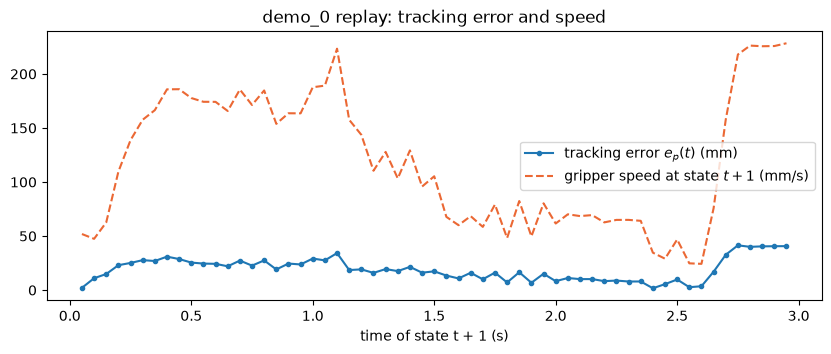

In [15]:
track = tracking_errors(replay)
speed = np.linalg.norm(replay["ach_linvel"][1:], axis=1)
t_end = replay["t_end"]

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(t_end, track[:, 0] * 1000, "o-", ms=3, label="tracking error $e_p(t)$ (mm)")
ax.plot(t_end, speed * 1000, "--", color="#eb6834", label="gripper speed at state $t+1$ (mm/s)")
ax.set(xlabel="time of state t + 1 (s)", title="demo_0 replay: tracking error and speed")
ax.legend()
plt.show()

The two curves have the same shape. When the gripper moves fast, the error is large. When the gripper stops, the error goes to almost zero. So the tracking error is mostly **lag**: the commanded goal runs ahead of the gripper, and the gripper follows behind it.

**The lag model.** The controller acts like a spring with a damper. It pulls the gripper toward the goal. When the goal moves at a constant speed $v$, a damped spring trails behind it by a constant distance:

$$
e_p \approx \tau \, \|v\|
$$

$\tau$ is the **lag time**. For this controller, the stiffness is $k_p = 150$ and the damping ratio is 1. A critically damped spring with these values has $\tau = 2/\sqrt{k_p} \approx 0.163$ s.

The next cell tests the model on all 200 replays. It fits $\tau$ by least squares through the origin, and it checks that the error points in the direction of motion.

controller: kp = 150, damping ratio = 1, predicted lag 2/sqrt(kp) = 0.163 s


fitted lag tau = 0.158 s, correlation of e_p with speed = 0.94
direction (speed > 20 mm/s): median cosine 0.98, 10th percentile 0.87


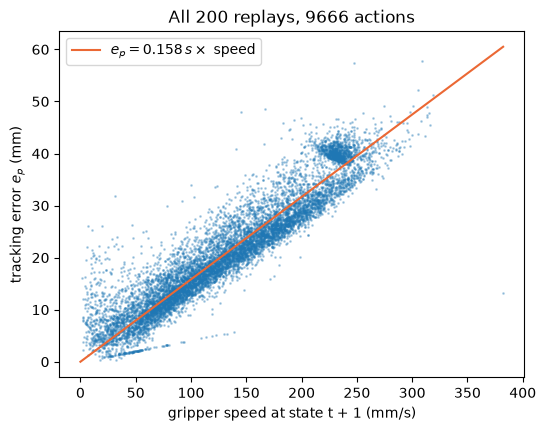

In [16]:
osc = json.loads(meta["env_args"])["env_kwargs"]["controller_configs"]["body_parts"]["right"]
print(f"controller: kp = {osc['kp']}, damping ratio = {osc['damping']}, predicted lag 2/sqrt(kp) = {2 / np.sqrt(osc['kp']):.3f} s")

err, spd, cos = [], [], []
with h5py.File(TRACES_PATH, "r") as f:
    for name in DEMOS:
        trace = read_trace(f[f"{name}/replay_absolute"])[0]
        vel = trace["ach_linvel"][1:]
        gap = trace["cmd_pos"] - trace["ach_pos"][1:]
        err.append(np.linalg.norm(gap, axis=1))
        spd.append(np.linalg.norm(vel, axis=1))
        # Cosine between the error vector and the velocity: 1 means the goal is straight ahead of the gripper.
        cos.append(np.sum(gap * vel, axis=1) / np.maximum(err[-1] * spd[-1], 1e-12))
err, spd, cos = map(np.concatenate, (err, spd, cos))

tau = np.sum(err * spd) / np.sum(spd**2)
moving = spd > 0.02
print(f"fitted lag tau = {tau:.3f} s, correlation of e_p with speed = {np.corrcoef(err, spd)[0, 1]:.2f}")
print(f"direction (speed > 20 mm/s): median cosine {np.median(cos[moving]):.2f}, 10th percentile {np.percentile(cos[moving], 10):.2f}")

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.plot(spd * 1000, err * 1000, ".", ms=2, alpha=0.3)
line = np.array([0, spd.max()])
ax.plot(line * 1000, tau * line * 1000, color="#eb6834", label=f"$e_p = {tau:.3f}\\,s \\times$ speed")
ax.set(xlabel="gripper speed at state t + 1 (mm/s)", ylabel="tracking error $e_p$ (mm)", title=f"All {len(DEMOS)} replays, {len(err)} actions")
ax.legend()
plt.show()

The fitted lag is about 0.16 s, almost the value that the spring model predicts. The error vector points along the velocity (median cosine near 1). So the goal is ahead of the gripper on its path, and the gap grows with the speed.

What this means for the Bézier work:
- **Tracking error is not a fit error.** It is a property of the controller and of the speed. A tracking error of 20 mm is normal here.
- A candidate with the **same speed profile** as the demonstration gets about the same tracking error. A candidate that moves faster has a larger error, even if its path is perfect.
- So compare a candidate's tracking error with the recording's tracking error at the same steps, not with zero. To judge whether the robot does the same thing, use the next metric.

The orientation error follows the same model. Fitted the same way against the angular speed, its lag is about 0.18 s, with a correlation of 0.88.

## 3.3 Achieved vs recording

$$
a(t) = \text{distance between state } t+1 \text{ of the trace and state } t+1 \text{ of the recording}
$$

`achieved_errors` computes it for five quantities:

| Column | Distance | What it shows |
| --- | --- | --- |
| `eef_pos_m` | position distance of the grip site | whether the gripper moves as in the demonstration |
| `eef_rot_rad` | geodesic angle of the grip site | the same, for orientation |
| `cube_pos_m` | position distance of the cube | whether the cube moves as in the demonstration |
| `cube_rot_rad` | geodesic angle of the cube | whether the cube tilts or turns differently |
| `finger_q_m` | largest difference of the two finger positions | whether the fingers close at the same time and to the same width |

**Why it is recorded.** Tracking error compares the robot with its own commands. This metric compares the outcome with the demonstration. Later, a Bézier candidate sends **different** commands. Its tracking error alone cannot say whether the robot did the same thing. This metric can.

**Why the baseline replay is not exactly zero.** The replay uses the stored commands, but it starts with a refreshed controller, and the recording started stale (Part 2). So the first step differs a little. The absolute goals pull the robot back to the commanded path, so the difference decays. The baseline replay therefore gives the **floor**: the smallest difference that any evaluation of these commands can have.

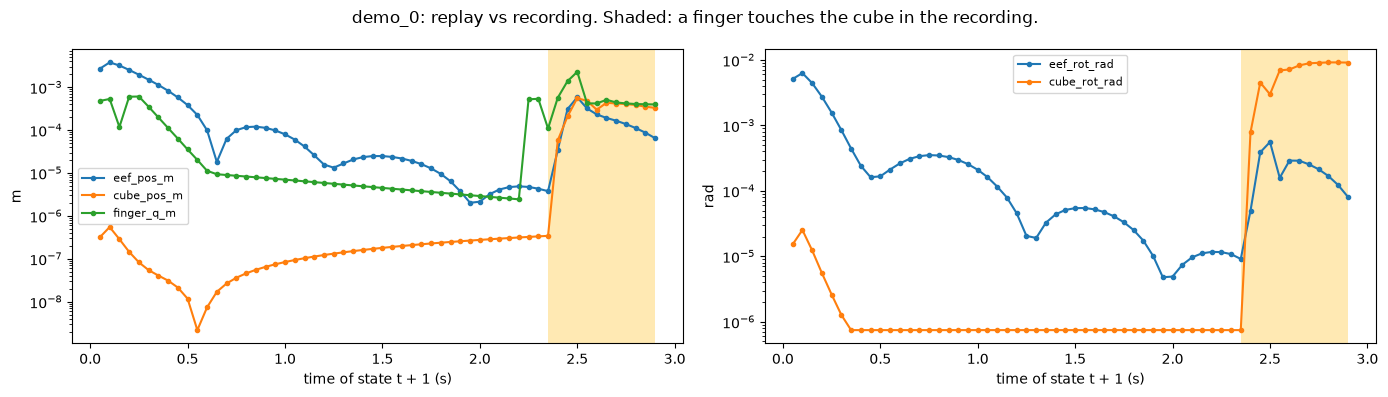

In [17]:
achieved = achieved_errors(replay, recorded)
contact = recorded["contact"][1:]

fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharex=True)
for ax, cols, unit in ((axes[0], (0, 2, 4), "m"), (axes[1], (1, 3), "rad")):
    for t in np.flatnonzero(contact):
        ax.axvspan(recorded["t_start"][t], recorded["t_end"][t], color="#ffe9b3", lw=0, zorder=0)
    for j in cols:
        ax.plot(t_end, np.maximum(achieved[:, j], 1e-16), "o-", ms=3, label=ACHIEVED_METRICS[j])
    ax.set(yscale="log", xlabel="time of state t + 1 (s)", ylabel=unit)
    ax.legend(fontsize=8)
fig.suptitle("demo_0: replay vs recording. Shaded: a finger touches the cube in the recording.")
fig.tight_layout()
plt.show()

How to read this plot:
- The gripper difference is a few millimetres in the first steps. Then it shrinks by about 1000 times before contact. That is the stale vs refreshed start, corrected by the absolute goals.
- Before contact, the cube difference is below 1e-6 m. Nothing touches the cube, so it rests in the same place in both runs.
- The finger difference jumps when the gripper command changes to close, a few steps before contact.
- During contact, the gripper pushes the cube. Small gripper differences become cube differences: the cube position differs by a few tenths of a millimetre, and its orientation by about 0.5°. In Part 3 of the earlier notebook, contact sometimes made a 1e-15 input difference grow to millimetres.

So a difference of a few tenths of a millimetre during contact is normal for the baseline. Part 4 gives the floor for all 200 demonstrations, per phase.

## 3.4 Task outcome

The outcome is read from two fields:
- `success`: whether the cube centre is more than 4 cm above the table top. It comes from robosuite's own `_check_success`, so it uses exactly the benchmark's rule.
- `cube_height`: how far above the table top the cube centre is. It shows **how much** the cube is lifted, and how close a failure came to the threshold.

**Where to read it.** The episodes never end early (`ignore_done` is True, and the horizon of 1000 steps is never reached). So the outcome is read at the **final state**:
- in a replay or candidate trace: state $N$, after the last action;
- in the recording: state $N-1$, its last valid state, because it has no state $N$.

Success at some earlier state is not enough. A cube that is lifted and then dropped is a failure, and Exercise 2 showed why the final state matters.

In [18]:
last = np.flatnonzero(recorded["valid"])[-1]
print(f"recording, state {last}: success {recorded['success'][last]}, cube height {recorded['cube_height'][last] * 100:.2f} cm")
print(f"replay,    state {n}: success {replay['success'][n]}, cube height {replay['cube_height'][n] * 100:.2f} cm")
print(f"first state with success: recording {np.argmax(recorded['success'])}, replay {np.argmax(replay['success'])}")

recording, state 58: success True, cube height 7.59 cm
replay,    state 59: success True, cube height 8.77 cm
first state with success: recording 55, replay 55


## 3.5 Phases and contact

`phase_labels(recorded, n)` gives each action one of five labels. The labels come from the **recording**, so every trace of the same demonstration uses the same labels, and their errors are compared over the same steps.

| Phase | Actions | Why it is separate |
| --- | --- | --- |
| `first` | $t = 0$ | its start is different in the recording and the replay |
| `approach` | from $t = 1$ until the first recorded contact | free motion, no contact |
| `grasp` | from the first contact until the lift rule is first met | the fingers close and the cube starts to rise; most sensitive to small differences |
| `lift` | after the lift rule is met | the cube is carried up |
| `final` | $t = N-1$ | the recording has no state after it |

Action $t$ belongs to a phase according to state $t+1$, the state where it is judged.

**Why split by phase.** Errors before contact and during contact have different sizes and different causes. If all steps were pooled, the many approach steps would hide a problem in the few grasp steps.

In [19]:
counts = {p: int((phases == p).sum()) for p in PHASES}
print(f"demo_0, N = {n}: {counts}")
print(f"states with recorded contact: {np.flatnonzero(recorded['contact']).tolist()}")
print(f"states with recorded success: {np.flatnonzero(recorded['success']).tolist()}")

demo_0, N = 59: {'first': 1, 'approach': 46, 'grasp': 7, 'lift': 4, 'final': 1}
states with recorded contact: [48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58]
states with recorded success: [55, 56, 57, 58]


In `demo_0`, most actions are in the approach. The grasp and lift together are only 11 actions, about 0.55 s. A metric that does not split by phase would be dominated by the approach.

**The summary statistics.** `summarize(values, phases, mask)` gives five numbers per phase and for all steps:

| Statistic | What it tells |
| --- | --- |
| `count` | how many steps were used (NaN steps and masked steps are left out) |
| `median` | the typical step |
| `rms` | root mean square; pulled up by a few large steps |
| `p95` | the 95th percentile; the size of the worst 5 % of steps |
| `max` | the single worst step |

When `rms` is much larger than `median`, a few steps are much worse than the rest. Look at `max` and find those steps in a plot.

In [20]:
not_first = np.arange(n) > 0
for label, values, mask in (("recorded", tracking_errors(recorded)[:, 0], not_first), ("replay", tracking_errors(replay)[:, 0], None)):
    stats = summarize(values, phases, mask)
    print(f"tracking position error, {label} (mm)")
    for phase, s in stats.items():
        print(f"  {phase:9s} count {s['count']:3d}  median {s['median'] * 1000:6.2f}  rms {s['rms'] * 1000:6.2f}  p95 {s['p95'] * 1000:6.2f}  max {s['max'] * 1000:6.2f}")

tracking position error, recorded (mm)
  approach  count  46  median  18.07  rms  20.01  p95  29.07  max  34.23
  grasp     count   7  median   5.61  rms  14.60  p95  27.95  max  32.65
  lift      count   4  median  40.53  rms  40.63  p95  41.30  max  41.42
  all       count  57  median  17.58  rms  21.57  p95  40.11  max  41.42
tracking position error, replay (mm)
  first     count   1  median   2.11  rms   2.11  p95   2.11  max   2.11
  approach  count  46  median  18.07  rms  19.94  p95  29.07  max  34.23
  grasp     count   7  median   5.51  rms  14.67  p95  27.98  max  32.68
  lift      count   4  median  40.53  rms  40.63  p95  41.30  max  41.43
  final     count   1  median  40.67  rms  40.67  p95  40.67  max  40.67
  all       count  59  median  17.58  rms  21.81  p95  40.48  max  41.43


The recording has no `first` row, because the mask leaves out $t = 0$. It also has no `final` row, because it has no state after the last action.

The saved figure `docs/diagnostics/figures/demo_0_errors.png` shows the same metrics over time. Contact steps are shaded, phase changes are marked, and a triangle marks each maximum.

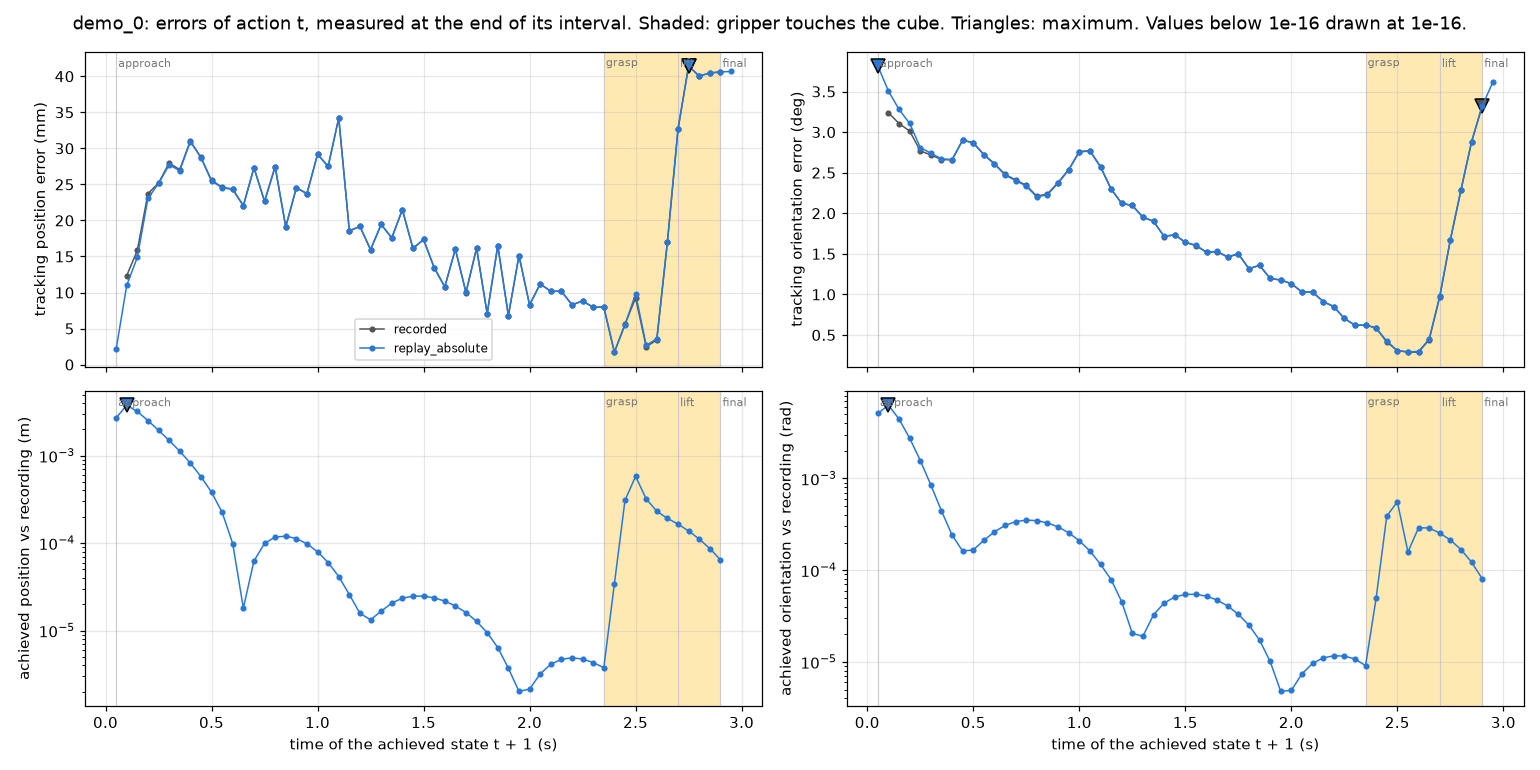

In [21]:
from IPython.display import Image

Image(filename=str(ROOT / "docs/diagnostics/figures/demo_0_errors.png"), width=1000)

## Part 3 summary

- The four metrics form a chain: **fidelity** → **tracking** → **achieved vs recording** → **outcome**. Check them in this order.
- **Command fidelity** is exactly zero in the baseline. A candidate must also give zero, or rounding-level values.
- **Tracking error** is mostly lag: $e_p \approx 0.16\,\text{s} \times$ speed, pointing along the motion. It depends on the speed profile, so it is not a measure of fit quality.
- **Achieved vs recording** compares the outcome with the demonstration. The baseline replay gives its floor. Contact makes small differences grow.
- **Outcome** is read at the final state, with `success` and `cube_height`.
- All per-step metrics are split by **phase**, with labels taken from the recording.

**Common mistake:** judging a candidate by its tracking error alone. A candidate that moves more slowly than the demonstration has a smaller tracking error, even if it follows a different path.

## Exercise 3

Use `demo_55`. Use the package functions from this part.

1. Find the largest command fidelity of its replay, for position and for orientation.
2. Use `summarize` to get the **median** tracking position error of the **recording** in each phase, in mm. Leave out $t = 0$. Which phase has the largest median?
3. Fit the lag time $\tau$ for the **replay** of `demo_55` alone, with the same least-squares formula as in section 3.2. Compare it with the all-demo value.
4. For replay vs recording, find the median `eef_pos_m` (in mm) and the median `cube_pos_m` (in mm) in each phase. In which phase is each one largest?
5. Suppose a Bézier candidate for `demo_55` has a median approach tracking error that is 5 mm larger than the recording's. In one or two sentences: is that a problem, and which other numbers would you check before you decide?

Write your answer in the next cell.
## Answers
5. I would also check the error values for each phase independently to get an idea of what factors other than Bezier fitting might be causing the error. 

In [22]:
# Your answer for Exercise 3.
rec55, replay55 = load_pair("demo_55")
fidelity55 = command_fidelity(replay55)
print(f"demo_55: max {fidelity55[:, 0].max():.1e} m, {fidelity55[:, 1].max():.1e} rad\n")

n = len(rec55["cmd_pos"])
phases = phase_labels(rec55, n)

not_first = np.arange(n) > 0
values55, mask = (tracking_errors(rec55)[:, 0], not_first)
stats = summarize(values55, phases, mask)
print(f"tracking position error, recorded (mm)")
for phase, s in stats.items():
    print(f"  {phase:9s} median {s['median'] * 1000:6.2f}\n")


trace55 = replay55
vel55 = trace55["ach_linvel"][1:]
gap55 = trace55["cmd_pos"] - trace55["ach_pos"][1:]
err55 = np.linalg.norm(gap55, axis=1)
spd55 = np.linalg.norm(vel55, axis=1)
# Cosine between the error vector and the velocity: 1 means the goal is straight ahead of the gripper.
cos55 = np.sum(gap55 * vel55, axis=1) / np.maximum(err55 * spd55, 1e-12)

tau55 = np.sum(err55 * spd55) / np.sum(spd55**2)
print(f"fitted lag tau for demo_55 = {tau55:.3f} s")
print(f"fitted lag tau for all demos = {tau:.3f} s\n")

achieved55 = achieved_errors(replay55, rec55)

cols = (0, 2)
for j in cols:
    stats = summarize(achieved55[:, j], phases)
    print(f"replay vs. recorded error in {ACHIEVED_METRICS[j]} (in mm)")
    largest_err = 0.0
    largest_err_phase = ''
    for phase, s in stats.items():
        print(f"  {phase:9s} median {s['median'] * 1000:6.2f}\n")
        if s['median'] > largest_err:
            largest_err = s['median']
            largest_err_phase = phase
    print(f"Largest error of {largest_err} mm during {largest_err_phase} pahse\n")

demo_55: max 0.0e+00 m, 0.0e+00 rad

tracking position error, recorded (mm)
  approach  median  17.47

  grasp     median  14.79

  lift      median  43.54

  all       median  17.47

fitted lag tau for demo_55 = 0.163 s
fitted lag tau for all demos = 0.158 s

replay vs. recorded error in eef_pos_m (in mm)
  first     median   3.45

  approach  median   0.07

  grasp     median   0.08

  lift      median   0.06

  all       median   0.07

Largest error of 0.0034529634563088434 mm during first pahse

replay vs. recorded error in cube_pos_m (in mm)
  first     median   0.00

  approach  median   0.00

  grasp     median   0.53

  lift      median  10.09

  all       median   0.00

Largest error of 0.010085388435837362 mm during lift pahse



---
# Part 4. The 200-demonstration baseline

Parts 1 to 3 used one or two demonstrations. Part 4 looks at all 200 together. Two questions are answered here:

1. **What is normal?** For each metric and phase, how large is the baseline value? A Bézier candidate is later compared with these numbers.
2. **Can the numbers be trusted?** What did the validation check, and which limits were changed?

The **baseline** is the replay of the stored absolute commands. It is the best result that any evaluation of these demonstrations can give, because it uses the demonstrator's own commands. A candidate that does as well as the baseline cannot be improved by a better fit.

## 4.1 The metrics file

`scripts/diagnostics_report.py` writes `docs/diagnostics/baseline_metrics.npz`. It has one row per action, for all 200 demonstrations together, so no trace has to be opened again:

| Key | Shape | Meaning |
| --- | --- | --- |
| `demo`, `t`, `phase` | (9666,) | demonstration name, action index, and phase of each row |
| `tracking_recorded` | (9666, 2) | $e_p$ (m) and $e_R$ (rad) of the recording; NaN at $t = 0$ and at the final action |
| `tracking_replay` | (9666, 2) | the same for the replay |
| `achieved_replay_vs_recorded` | (9666, 5) | the five columns of `achieved_errors`; NaN at the final action |
| `demo_names`, `lift_recorded`, `lift_replay`, `final_height_replay` | (200,) | one row per demonstration: the outcome |

In [23]:
BASE = np.load(ROOT / "docs/diagnostics/baseline_metrics.npz")
b_demo, b_t, b_phase = BASE["demo"], BASE["t"], BASE["phase"]
b_track_rec, b_track_rep = BASE["tracking_recorded"], BASE["tracking_replay"]
b_achieved = BASE["achieved_replay_vs_recorded"]
print({k: BASE[k].shape for k in BASE.files})
print("steps per phase:", {p: int((b_phase == p).sum()) for p in PHASES})

{'demo': (9666,), 't': (9666,), 'phase': (9666,), 'tracking_recorded': (9666, 2), 'tracking_replay': (9666, 2), 'achieved_replay_vs_recorded': (9666, 5), 'achieved_metrics': (5,), 'demo_names': (200,), 'lift_recorded': (200,), 'lift_replay': (200,), 'final_height_replay': (200,)}
steps per phase: {'first': 200, 'approach': 7045, 'grasp': 1416, 'lift': 805, 'final': 200}


The approach has about 73 % of all steps. The grasp and lift phases together have about 23 %. So pooled numbers mostly describe the approach.

## 4.2 Task outcome

lifted at the final state: recording 200 of 200, replay 199 of 200
replay failures: ['demo_177']
final cube height of successful replays: min 5.70 cm, median 8.97 cm


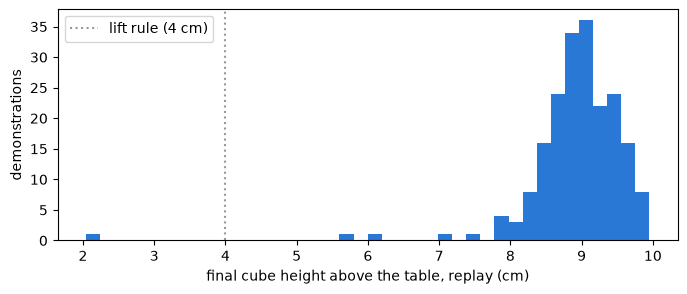

In [24]:
lift_rec, lift_rep, height = BASE["lift_recorded"], BASE["lift_replay"], BASE["final_height_replay"] * 100
print(f"lifted at the final state: recording {lift_rec.sum()} of {len(lift_rec)}, replay {lift_rep.sum()} of {len(lift_rep)}")
print("replay failures:", BASE["demo_names"][~lift_rep].tolist())
print(f"final cube height of successful replays: min {height[lift_rep].min():.2f} cm, median {np.median(height[lift_rep]):.2f} cm")

fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(height, bins=40, color="#2a78d6")
ax.axvline(4, color="#999999", ls=":", label="lift rule (4 cm)")
ax.set(xlabel="final cube height above the table, replay (cm)", ylabel="demonstrations")
ax.legend()
plt.show()

- The recording lifts the cube in all 200 demonstrations. The replay lifts it in 199.
- The one failure is `demo_177`, which you looked at in Exercise 2.
- Every successful replay ends at least about 1.7 cm above the threshold. So "success" is not decided by a few millimetres: a candidate either lifts the cube clearly or fails clearly.

**What this means for a candidate.** The baseline success rate is 199 of 200, not 200 of 200. A candidate that fails on `demo_177` does not show a fitting problem. Compare a candidate's failures with the baseline's failures, demonstration by demonstration.

## 4.3 Tracking error across all demonstrations

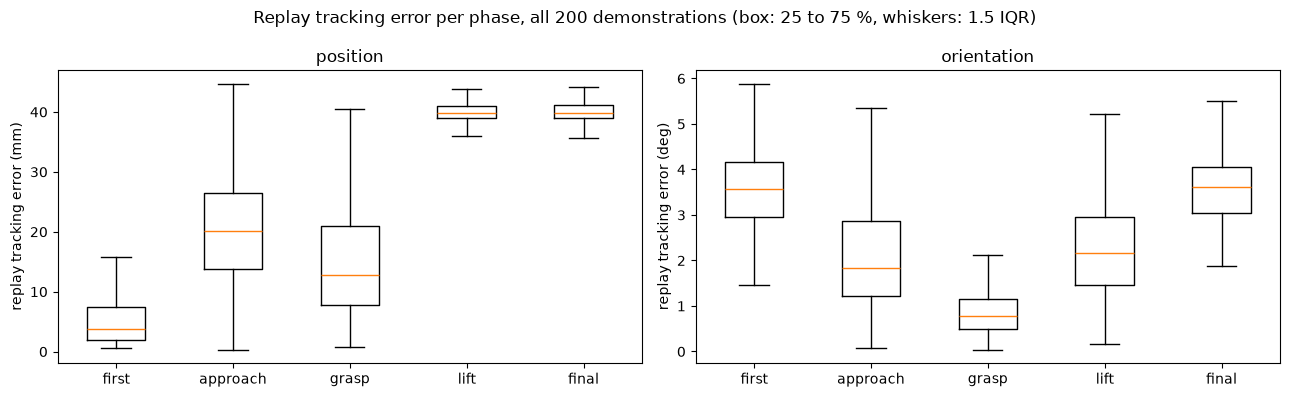

recorded vs replay tracking error, same steps: median |difference| 0.018 mm


In [25]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, j, scale, unit in ((axes[0], 0, 1000, "mm"), (axes[1], 1, np.degrees(1.0), "deg")):
    data = [b_track_rep[(b_phase == p) & np.isfinite(b_track_rep[:, j]), j] * scale for p in PHASES]
    ax.boxplot(data, showfliers=False)
    ax.set_xticks(range(1, len(PHASES) + 1), PHASES)
    ax.set(ylabel=f"replay tracking error ({unit})", title=["position", "orientation"][j])
fig.suptitle("Replay tracking error per phase, all 200 demonstrations (box: 25 to 75 %, whiskers: 1.5 IQR)")
fig.tight_layout()
plt.show()

both = np.isfinite(b_track_rec[:, 0]) & np.isfinite(b_track_rep[:, 0])
print(f"recorded vs replay tracking error, same steps: median |difference| {np.median(np.abs(b_track_rec[both, 0] - b_track_rep[both, 0])) * 1000:.3f} mm")

Read this with the lag model of Part 3 ($e_p \approx 0.16\,\text{s} \times$ speed):
- **first:** small. The robot starts at rest, so it has no speed yet and no lag.
- **approach:** about 20 mm. The gripper moves toward the cube at normal speed.
- **grasp:** the smallest median. The demonstrator slows down to close the fingers. But the spread is wide, because the cube also starts to rise in this phase.
- **lift** and **final:** about 40 mm. The demonstrator lifts quickly, so the lag is large.

The recording and the replay have almost the same tracking error at the same steps. So the tracking error of the recording is a good reference for a candidate, step by step.

## 4.4 Replay vs recording: the floor

This is the smallest difference from the recording that any evaluation can expect, because the baseline uses the demonstrator's own commands.

In [26]:
rows = [("eef_pos", 0, 1000, "mm"), ("eef_rot", 1, np.degrees(1.0), "deg"), ("cube_pos", 2, 1000, "mm"), ("cube_rot", 3, np.degrees(1.0), "deg"), ("finger_q", 4, 1000, "mm")]
print(f"{'metric':10s}{'phase':10s}{'median':>10s}{'p95':>10s}{'max':>10s}")
for label, j, scale, unit in rows:
    stats = summarize(b_achieved[:, j], b_phase)
    for phase in ("first", "approach", "grasp", "lift"):
        s = stats[phase]
        print(f"{label:10s}{phase:10s}{s['median'] * scale:10.3g}{s['p95'] * scale:10.3g}{s['max'] * scale:10.3g}  {unit}")

metric    phase         median       p95       max
eef_pos   first           2.66      5.33      8.15  mm
eef_pos   approach      0.0576      2.86      11.5  mm
eef_pos   grasp          0.133      0.73      1.78  mm
eef_pos   lift          0.0961     0.439      1.22  mm
eef_rot   first          0.368     0.761     0.982  deg
eef_rot   approach     0.00976     0.347      1.25  deg
eef_rot   grasp        0.00759    0.0352    0.0898  deg
eef_rot   lift         0.00576    0.0288    0.0715  deg
cube_pos  first              0  0.000337  0.000352  mm
cube_pos  approach           0  0.000167     0.336  mm
cube_pos  grasp          0.431       1.9      11.3  mm
cube_pos  lift           0.982      3.47      56.1  mm
cube_rot  first       1.31e-16  0.000937  0.000981  deg
cube_rot  approach    4.67e-15  4.35e-05     0.247  deg
cube_rot  grasp          0.306      2.29      15.3  deg
cube_rot  lift           0.854      3.07      18.6  deg
finger_q  first          0.472     0.503      0.54  mm
finger

Two patterns stand out:
- **Gripper (eef):** the median is about 0.1 mm or less in the approach, grasp, and lift phases. But in the approach, the 95th percentile is about 3 mm and the maximum about 11 mm. The next cell shows where those large values come from.
- **Cube:** exactly zero before contact, because nothing touches the cube. In the grasp and lift phases, the median is about 0.5 to 1 mm and the angle about 0.3 to 0.9°. Contact makes small differences grow.

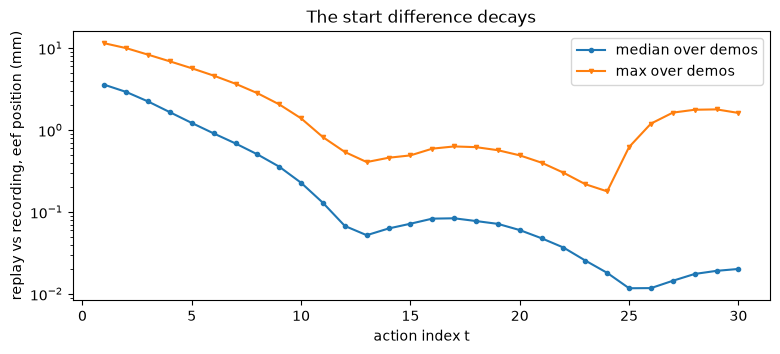

approach steps above 2 mm: 578, all at t <= 9
approach, all steps    count  7045  median 0.058  p95 2.864  max 11.451 mm
approach, t >= 10      count  5245  median 0.030  p95 0.207  max 1.386 mm


In [27]:
eef = b_achieved[:, 0] * 1000
ts = np.arange(1, 31)
med = [np.nanmedian(eef[b_t == t]) for t in ts]
mx = [np.nanmax(eef[b_t == t]) for t in ts]

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.semilogy(ts, med, "o-", ms=3, label="median over demos")
ax.semilogy(ts, mx, "v-", ms=3, label="max over demos")
ax.set(xlabel="action index t", ylabel="replay vs recording, eef position (mm)", title="The start difference decays")
ax.legend()
plt.show()

approach = b_phase == "approach"
print(f"approach steps above 2 mm: {np.sum(approach & (eef > 2))}, all at t <= {b_t[approach & (eef > 2)].max()}")
for label, mask in (("approach, all steps", approach), ("approach, t >= 10", approach & (b_t >= 10))):
    s = summarize(b_achieved[:, 0], b_phase, mask)["approach"]
    print(f"{label:22s} count {s['count']:5d}  median {s['median'] * 1000:.3f}  p95 {s['p95'] * 1000:.3f}  max {s['max'] * 1000:.3f} mm")

The large approach differences all come from the **first few steps**. They are the stale vs refreshed start of Part 2: the recording and the replay start with different controller goals at $t = 0$. The absolute goals then pull both onto the same path, and the median difference shrinks by about 50 times in the first 15 steps.

So the phase labels mix two things in the approach: a **start transient** (about $t < 10$) and the **settled** motion after it. When a candidate is compared with the floor, compare these two parts separately. Otherwise the start transient hides any real difference in the settled part.

The largest cube differences:

In [28]:
cube = b_achieved[:, 2] * 1000
worst = sorted(((np.nanmax(cube[b_demo == d]), d) for d in BASE["demo_names"]), reverse=True)[:5]
for value, d in worst:
    k = int(np.flatnonzero(BASE["demo_names"] == d)[0])
    print(f"{d:9s} max cube difference {value:6.2f} mm   replay lifted: {lift_rep[k]}   final height {height[k]:.2f} cm")

demo_177  max cube difference  56.08 mm   replay lifted: False   final height 2.04 cm
demo_55   max cube difference  10.13 mm   replay lifted: True   final height 8.26 cm
demo_198  max cube difference   6.64 mm   replay lifted: True   final height 8.50 cm
demo_193  max cube difference   5.76 mm   replay lifted: True   final height 8.57 cm
demo_159  max cube difference   5.59 mm   replay lifted: True   final height 8.47 cm


One demonstration has a cube difference of several centimetres: the replay failure. Others have differences of 5 mm to 1 cm and still lift the cube. A cube difference alone does not mean failure. Use it together with the outcome.

## 4.5 What the validation proved

`scripts/validate_diagnostics.py` checked every trace before any metric was used. Each check rules out one way that the metrics could be wrong:

| Check | Limit | What it rules out |
| --- | --- | --- |
| time | 1e-9 s | wrong alignment: a command compared with the wrong state |
| command fidelity | 1e-8 | the controller following something other than our command |
| frame | 1e-9 m, **1e-6 rad** | measuring the wrong point or the wrong frame (for example, the hand body) |
| completeness | 1e-9 | missing rows, NaN in valid rows, rotation matrices that are not rotations |
| reproducibility | 1e-12 | a baseline that differs from Experiment B, which used the same start and commands |
| rotation | slack 1e-9 rad | rotation errors that jump with the stored rotation vectors (the 2π problem of Part 1) |
| velocity | 1e-10 | a wrong velocity readout |
| geodesic | 1e-6 rad | a wrong distance function near π |

All checks passed on all 200 demonstrations.

In [29]:
report = (ROOT / "docs/diagnostics/validation_report.md").read_text()
print([line for line in report.splitlines() if line.startswith(("Overall", "Geodesic"))])

['Geodesic angle on 2050 test rotations up to pi - 1e-6: largest error 8.9e-16 rad (limit 1e-06), pass.', 'Overall: pass.']


**Three limits were changed from the original plan.** Each change has a physical reason. None was made to hide a failure:

1. **Frame orientation: 1e-9 → 1e-6 rad.** The dataset stores the site quaternion as float32 (Part 2). Its rounding is about 4e-7 rad. A 1e-9 limit cannot be met by any correct reading.
2. **Rotation: a fixed 0.1 rad limit → the triangle bound.** The first version said: where the stored rotation vector jumps, $e_R$ must change by less than 0.1 rad. It failed on 5 demonstrations. There, the commands really turn by 0.12 to 0.25 rad in one step. The new check uses the largest change that is physically possible:
   $$
   |e_R(t) - e_R(t-1)| \le d(R^{cmd}_{t-1}, R^{cmd}_t) + d(R^{ach}_t, R^{ach}_{t+1})
   $$
   A real 2π jump in the metric would break this bound by about 6 rad. The largest value over the 53 demonstrations with jumps is −0.0016 rad, so the bound holds everywhere.
3. **Velocity: finite differences → Jacobian × joint speeds.** The first version compared the stored velocity with the change of pose over 0.05 s. That compares an instant with an average, so it failed on `demo_156` (relative error 0.21) during fast changes. The new check computes the same instant two ways, and agrees to 3.3e-16. The finite-difference values are still in the report, for information only.

## Part 4 summary

- The baseline replay lifts the cube in **199 of 200**. The failure is `demo_177`. Successes end at least 1.7 cm above the threshold.
- Tracking error per phase follows the lag model: small at the start, about 20 mm in the approach, smallest median in the grasp, about 40 mm in the lift.
- The replay's tracking error matches the recording's at the same steps. So the recording is a step-by-step reference.
- **The floor** for replay vs recording: gripper about 0.1 mm or less (median) after the start transient; cube exactly 0 before contact, and about 0.5 to 1 mm in contact.
- The approach has a **start transient** for $t < 10$. Compare it separately from the settled part.
- The validation passed everywhere. Three limits were changed for physical reasons: float32 storage, real large rotations, and instant vs average velocity.

**Common mistake:** comparing a candidate with zero. Compare it with the baseline, per phase, and demonstration by demonstration.

## Exercise 4

Use `baseline_metrics.npz` (the arrays loaded in section 4.1). Do not open the traces file.

1. For each phase, find the fraction of steps where the replay vs recording **eef position** difference is below 0.1 mm.
2. Find the first action index $t$ after which the **median** eef position difference over all demonstrations stays below 0.1 mm for every later $t$ up to 30. Is this consistent with the cut at $t = 10$ in section 4.4?
3. For each demonstration, take the largest **cube position** difference in the grasp and lift phases. How many demonstrations have it above 2 mm? How many of those still lift the cube?
4. Write a pass rule for a Bézier candidate on **one** demonstration, using the baseline numbers. It needs at least: a fidelity limit, a gripper limit for the settled approach, a limit for the contact phases, and an outcome rule. In two or three sentences, say why each limit has the value you chose.

Write your answer in the next cell.

In [30]:
# Your answer for Exercise 4.
print(f"Fraction of eef position difference below 0.1 mm")
for phase in ("first", "approach", "grasp", "lift"):
    eef_pos_diff_phase = b_achieved[b_phase == phase, 0]
    threshold_mask = (eef_pos_diff_phase < 0.0001) | np.isnan(eef_pos_diff_phase)
    print(f"  {phase}: {threshold_mask.mean():.2f}")
print("")

med = [np.nanmedian(eef[b_t == t]) for t in ts]
high_err_idxs = [i+1 for i, x in enumerate(med) if x > 0.1]
print(f"First action index after which eef position difference for all demos is below 0.1 mm: {high_err_idxs[-1]+1}.\n")

cube = b_achieved[:, 2] * 1000
grasp_worst = sorted(((np.nanmax(cube[(b_demo == d) & (b_phase == 'grasp')]), d) for d in BASE["demo_names"]))
grasp_is_above_2 = []
for value, d in grasp_worst:
    if value > 2:
        grasp_is_above_2.append(d)

lift_worst = sorted(((np.nanmax(cube[(b_demo == d) & (b_phase == 'lift')]), d) for d in BASE["demo_names"]))
lift_is_above_2 = []
for value, d in lift_worst:
    if value > 2:
        lift_is_above_2.append(d)

print("Number of demos with largest cube position difference > 2 mm")
print(f"  grasp: {len(grasp_is_above_2)}")
print(f"  lift: {len(lift_is_above_2)}\n")

grasp_is_above_2_lifted = []
lift_is_above_2_lifted = []
for d in grasp_is_above_2:
    k = int(np.flatnonzero(BASE["demo_names"] == d)[0])
    if lift_rep[k]:
        grasp_is_above_2_lifted.append(d)
for d in lift_is_above_2:
    k = int(np.flatnonzero(BASE["demo_names"] == d)[0])
    if lift_rep[k]:
        lift_is_above_2_lifted.append(d)
print("Number of demos with cube pos diff > 2 mm but still lift the cube")
print(f"  grasp: {len(grasp_is_above_2_lifted)}")
print(f"  lift: {len(lift_is_above_2_lifted)}\n")

Fraction of eef position difference below 0.1 mm
  first: 0.00
  approach: 0.62
  grasp: 0.42
  lift: 0.52

First action index after which eef position difference for all demos is below 0.1 mm: 12.

Number of demos with largest cube position difference > 2 mm
  grasp: 34
  lift: 24

Number of demos with cube pos diff > 2 mm but still lift the cube
  grasp: 33
  lift: 23



## 4.6 A pass rule for Bézier candidates

This section records the pass rule agreed after Exercise 4, as updated after Part 5. Part 6 uses it.

**The reference is a replay, not the recording.** A candidate is compared with a replay of the same demonstration. After Part 5, the fit starts at the actual start pose (section 5.7). So the reference is the replay of the stored actions with action 0 replaced by the start pose (`replay_q0start`, built and confirmed in hypothesis H21, section 6.1). With the matching reference:
- Both runs start with a refreshed controller from the same state 0. So every difference comes from the commands, and the start transient of section 4.4 does not occur.
- The replay has state $N$, so the `final` phase can also be compared.
- If the candidate's commands equal the stored commands, every difference is exactly 0.

So the floor numbers of section 4.4 (replay vs recording) do **not** set the limits. They describe the different start, not the fit. The limits come from how much fit error the task can accept.

**Tracking error is not a limit.** It depends on the speed profile (Part 3). A candidate that does not move has no lag, and a candidate on the wrong path at the same speed has the same lag. The limits are on the **difference from the replay** at the same state.

**The rule, per demonstration:**

| Level | Metric | Rule | Why |
| --- | --- | --- | --- |
| 0. Input | command fidelity | max ≤ 1e-9 m and ≤ 1e-9 rad | the controller must receive the curve that we sent; the rotation conversion changes values by only about 1e-15 |
| 1. Fit | command difference, Bézier vs stored, per action | report only, no limit | section 5.6: no smooth curve can follow the command jitter, and the controller removes it anyway |
| 2. Free motion | achieved gripper difference, actions before the replay's first contact | max ≤ 3 mm and ≤ 1° (proposed) | the controller smooths the commands, so the achieved difference cannot be larger than the command difference; 3 mm is small against the clearance (below) |
| 3. Contact | achieved gripper difference in grasp, lift, and final | max ≤ 3 mm and ≤ 1° (proposed) | the fingers must close at the same place |
| 3. Contact | step where the gripper command changes | round($T_{pre}$ / 0.05 s) equals the replay's close step | the fingers must close at the same time; the switch can only happen at an action boundary |
| 3. Contact | cube position and angle difference | report only; flag the demonstration when it is above the sensitivity limit (below) | in contact, tiny input differences can grow to millimetres, so a fixed limit would fail good candidates |
| 4. Outcome | `success` at state $N$, and final cube height | must lift wherever the replay lifts; report the height difference | the task itself |
| diagnostic | tracking error vs the replay, per action | not pass or fail | a large change means a different speed profile |

**The clearance.** The Lift cube is 4.0 to 4.4 cm wide. The open fingers are about 7.8 cm apart. So the gripper has about 1.7 cm free on each side of the cube. A deviation of 20 mm at the grasp could make a finger close on the edge of the cube, or miss it.

**The rule over all demonstrations.** Count the demonstrations where the candidate and the replay disagree on success, in each direction. A candidate passes only if there is none where the replay lifts the cube and the candidate does not. Inspect every disagreement. `demo_177` fails in the replay, so a failure there is not a fit problem.

**Open items.** The 3 mm and 1° limits are proposals, not measurements. The cube sensitivity limit is not known yet. A perturbation sweep (hypothesis H22), run against `replay_q0start`, will measure both:
1. Add small errors (0.1, 0.3, 1, and 3 mm, with matching angles) to the stored commands.
2. Evaluate each set against the replay.
3. Measure how the gripper difference, the cube difference, and the success rate grow with the error.

The largest error that keeps the success rate of the replay sets the fit limits. The cube differences at small errors set the sensitivity limit.

---
# Part 5. Properties of the fitting target

The Bézier curves will be fitted to the **commanded** poses $(p^{cmd}_t, R^{cmd}_t)$, not to the achieved poses. Part 3 showed why: the commands lead the gripper by about 0.16 s. A curve fitted to the achieved poses would arrive about 0.16 s late.

Part 5 looks at the commanded sequences **before** any fit. The fitting plan (`docs/manifold_bezier_control_point_extraction_plan.md`) uses:
- $K$ cubic segments, with equally spaced knots on a normalized time $t_i = i/(N-1) \in [0, 1]$;
- $C^1$ continuity at the knots;
- the first and last commands as **fixed endpoints**.

Each of these choices meets a property of the data. This part measures those properties:

| Section | Property | Fitting choice it affects |
| --- | --- | --- |
| 5.1 | episode lengths and phase timing | normalized time, number of segments $K$ |
| 5.2 | step sizes | how much the curve moves per action |
| 5.3 | jaggedness | how close a smooth curve can come |
| 5.4 | the first command | the fixed start point |
| 5.5 | the gripper | what the curve does not represent |
| 5.6 | a rough fit preview | $K$, and the fit limit of section 4.6 |
| 5.7 | decisions | the knot layout and the fixed start |

The next cell reads what Part 5 needs from all 200 replay traces once.

In [31]:
CMD = {}
with h5py.File(TRACES_PATH, "r") as f:
    for name in DEMOS:
        rec = read_trace(f[f"{name}/recorded"])[0]
        rep = read_trace(f[f"{name}/replay_absolute"])[0]
        n_act = len(rep["cmd_pos"])
        switch = int(np.flatnonzero(np.diff(rep["gripper_cmd"]))[0]) + 1
        CMD[name] = {
            "N": n_act,
            "cmd_pos": rep["cmd_pos"],
            "cmd_rot": rep["cmd_rot"],
            "ach_pos": rep["ach_pos"],
            "ach_rot": rep["ach_rot"],
            "gripper_cmd": rep["gripper_cmd"],
            "switches": int(np.count_nonzero(np.diff(rep["gripper_cmd"]))),
            "switch": switch,
            "first_contact": int(np.argmax(rec["contact"])),
            "phases": phase_labels(rec, n_act),
        }
print(f"read {len(CMD)} demonstrations")

read 200 demonstrations


## 5.1 Episode lengths and phase timing

Each demonstration is mapped to normalized time: command $i$ is at $t_i = i/(N-1)$, so the first command is at 0 and the last at 1. With $K$ equal segments, each segment covers $1/K$ of the demonstration. But the demonstrations have different lengths, so one segment covers a different number of actions, and a different duration in seconds, in each one.

N: min 36, median 48, max 64 actions (1.80 to 3.20 s)
K =  3: actions per segment  11.7 to  21.0, duration 0.58 to 1.05 s
K =  5: actions per segment   7.0 to  12.6, duration 0.35 to 0.63 s
K =  8: actions per segment   4.4 to   7.9, duration 0.22 to 0.39 s
K = 10: actions per segment   3.5 to   6.3, duration 0.18 to 0.32 s


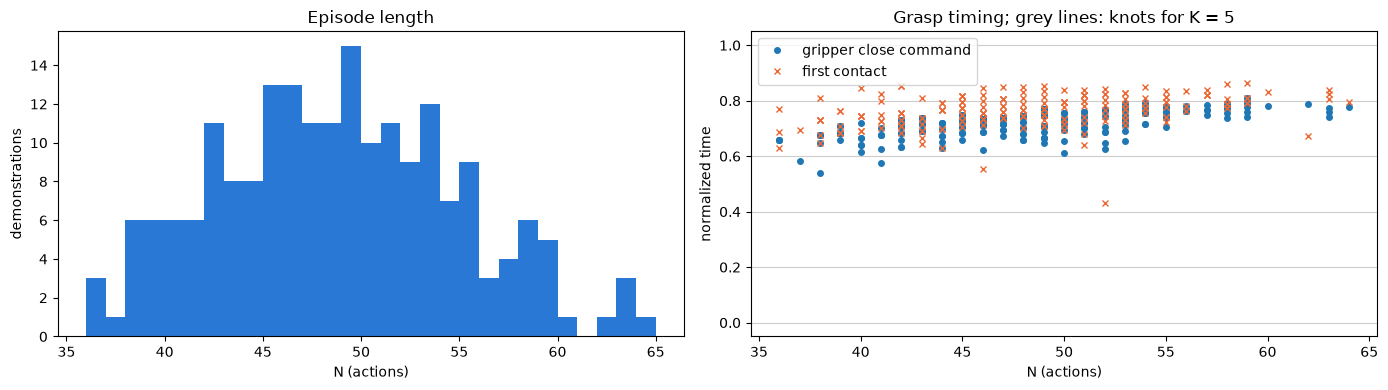

gripper close command at normalized time 0.54 to 0.81


In [32]:
Ns = np.array([CMD[d]["N"] for d in DEMOS])
print(f"N: min {Ns.min()}, median {np.median(Ns):.0f}, max {Ns.max()} actions ({Ns.min() * CONTROL_DT:.2f} to {Ns.max() * CONTROL_DT:.2f} s)")
for K in (3, 5, 8, 10):
    per_seg = (Ns - 1) / K
    print(f"K = {K:2d}: actions per segment {per_seg.min():5.1f} to {per_seg.max():5.1f}, duration {per_seg.min() * CONTROL_DT:.2f} to {per_seg.max() * CONTROL_DT:.2f} s")

# Command t is judged at state t + 1, so the first contact at state k belongs to command k - 1.
switch_u = np.array([CMD[d]["switch"] / (CMD[d]["N"] - 1) for d in DEMOS])
contact_u = np.array([(CMD[d]["first_contact"] - 1) / (CMD[d]["N"] - 1) for d in DEMOS])

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(Ns, bins=range(Ns.min(), Ns.max() + 2), color="#2a78d6")
axes[0].set(xlabel="N (actions)", ylabel="demonstrations", title="Episode length")
axes[1].plot(Ns, switch_u, "o", ms=4, label="gripper close command")
axes[1].plot(Ns, contact_u, "x", ms=4, color="#eb6834", label="first contact")
for u in np.linspace(0, 1, 6):
    axes[1].axhline(u, color="#cccccc", lw=0.8, zorder=0)
axes[1].set(xlabel="N (actions)", ylabel="normalized time", title="Grasp timing; grey lines: knots for K = 5")
axes[1].legend()
fig.tight_layout()
plt.show()
print(f"gripper close command at normalized time {switch_u.min():.2f} to {switch_u.max():.2f}")

- The longest demonstration is about 1.8 times the shortest. With equal knots, one segment holds about 7 actions in a short demonstration and about 13 in a long one (for $K = 5$).
- The grasp happens between about 55 % and 80 % of the normalized time. So the grasp does not always fall in the same segment, and it can fall close to a knot.
- The grasp and lift together are only about 11 actions (Part 3). With $K = 5$, that is about one segment. The curve must be exact in the part where Part 4 showed that the outcome is most sensitive, and that part gets the fewest control points.

## 5.2 Step sizes

How far does the command move from one action to the next?

In [33]:
pos_step = np.concatenate([np.linalg.norm(np.diff(CMD[d]["cmd_pos"], axis=0), axis=1) for d in DEMOS])
rot_step = np.concatenate([geodesic(CMD[d]["cmd_rot"][:-1], CMD[d]["cmd_rot"][1:]) for d in DEMOS])
print(f"position step: median {np.median(pos_step) * 1000:.1f} mm, p95 {np.percentile(pos_step, 95) * 1000:.1f} mm, max {pos_step.max() * 1000:.1f} mm")
print(f"rotation step: median {np.degrees(np.median(rot_step)):.2f} deg, p95 {np.degrees(np.percentile(rot_step, 95)):.2f} deg, max {np.degrees(rot_step.max()):.1f} deg")
print(f"steps below 0.5 mm (the command stands still): {np.mean(pos_step < 5e-4) * 100:.2f} %")

with h5py.File(SOURCE_PATH, "r") as src:
    deltas = np.concatenate([src[f"data/{d}/actions"][:, :6] for d in DEMOS])
print(f"original delta actions at the +-1 input limit on some axis: {np.mean(np.abs(deltas).max(axis=1) >= 0.999) * 100:.1f} %")

position step: median 9.7 mm, p95 20.3 mm, max 74.8 mm
rotation step: median 0.50 deg, p95 1.48 deg, max 30.3 deg
steps below 0.5 mm (the command stands still): 0.03 %


original delta actions at the +-1 input limit on some axis: 9.5 %


- A typical command step is about 1 cm and 0.5°. That is half of the 20 mm tracking error: the goal is about two steps ahead of the gripper.
- The command almost never stands still. The demonstrator moves all the time, from the first action to the last.
- About 1 in 10 of the original delta actions is at the input limit of the 3D mouse on some axis. In those steps, the demonstrator wanted to move faster than the device allowed.
- The largest steps are several times the p95. Most of the largest rotation steps are at $t = 1$ (section 5.4).

## 5.3 Jaggedness

Part 1 showed that the commanded path is jagged and the achieved path is smooth. The **second difference** measures this: $\Delta^2 p_t = p_{t+1} - 2p_t + p_{t-1}$. It is zero on a straight line at constant speed, and large where the path changes direction or speed suddenly.

second difference, median: commanded 9.28 mm, achieved 1.03 mm, ratio 9.0


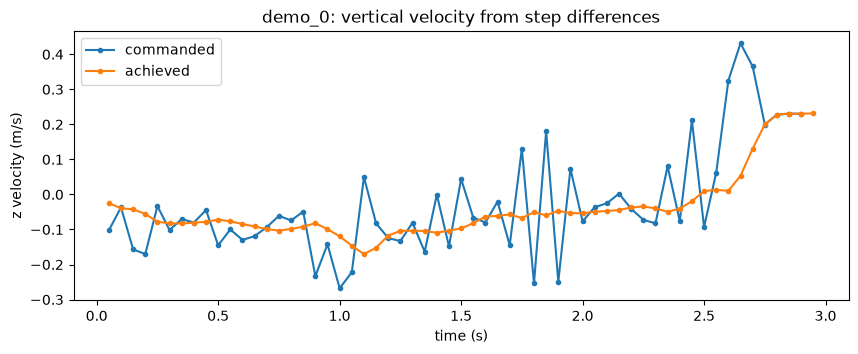

In [34]:
d2_cmd = np.concatenate([np.linalg.norm(np.diff(CMD[d]["cmd_pos"], 2, axis=0), axis=1) for d in DEMOS])
d2_ach = np.concatenate([np.linalg.norm(np.diff(CMD[d]["ach_pos"], 2, axis=0), axis=1) for d in DEMOS])
print(f"second difference, median: commanded {np.median(d2_cmd) * 1000:.2f} mm, achieved {np.median(d2_ach) * 1000:.2f} mm, ratio {np.median(d2_cmd) / np.median(d2_ach):.1f}")

d = CMD["demo_0"]
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(CONTROL_DT * np.arange(1, d["N"]), np.diff(d["cmd_pos"][:, 2]) / CONTROL_DT, "o-", ms=3, label="commanded")
ax.plot(CONTROL_DT * np.arange(1, d["N"] + 1), np.diff(d["ach_pos"][:, 2]) / CONTROL_DT, "o-", ms=3, label="achieved")
ax.set(xlabel="time (s)", ylabel="z velocity (m/s)", title="demo_0: vertical velocity from step differences")
ax.legend()
plt.show()

The commanded path changes direction or speed about 9 times more sharply than the achieved path. The commanded velocity jumps from step to step. The achieved velocity is smooth.

The jitter comes from the demonstrator's hand on the 3D mouse. The controller acts as a low-pass filter (Part 3), so the robot does not follow it. This matters for the fit:
- A $C^1$ cubic curve with a few segments **cannot** follow this jitter. It will pass through the middle of it.
- It **does not need to**. The controller removes most of the jitter anyway.
- So the difference between the fitted curve and the commands will be larger than the difference between the achieved motions. Section 5.6 measures the first. The evaluation of Part 6 measures the second.

## 5.4 The first command

The fitting plan fixes the curve's start to the first command: $q_0 = (p^{cmd}_0, R^{cmd}_0)$. The first command is "the actual start pose plus the first delta" (the decision recorded with H17). How does it compare with the start pose, and with the next command?

command 0 vs start pose: position is exactly 0 in 50.5 % of demos; max 64.8 mm
command 0 vs start pose: rotation median 4.01 deg, max 28.7 deg
rotation step from command 0 to command 1: median 0.50 deg, above 5 deg in 20 demos
median rotation step after t = 1, median over demos: 0.52 deg


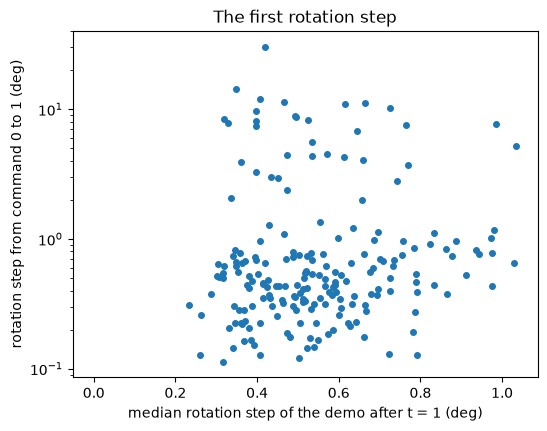

In [35]:
first_pos = np.array([np.linalg.norm(CMD[d]["cmd_pos"][0] - CMD[d]["ach_pos"][0]) for d in DEMOS])
first_rot = np.array([geodesic(CMD[d]["cmd_rot"][:1], CMD[d]["ach_rot"][:1])[0] for d in DEMOS])
step01 = np.array([geodesic(CMD[d]["cmd_rot"][:1], CMD[d]["cmd_rot"][1:2])[0] for d in DEMOS])
step_rest = np.array([np.median(geodesic(CMD[d]["cmd_rot"][1:-1], CMD[d]["cmd_rot"][2:])) for d in DEMOS])

print(f"command 0 vs start pose: position is exactly 0 in {np.mean(first_pos == 0) * 100:.1f} % of demos; max {first_pos.max() * 1000:.1f} mm")
print(f"command 0 vs start pose: rotation median {np.degrees(np.median(first_rot)):.2f} deg, max {np.degrees(first_rot.max()):.1f} deg")
print(f"rotation step from command 0 to command 1: median {np.degrees(np.median(step01)):.2f} deg, above 5 deg in {np.sum(step01 > np.radians(5))} demos")
print(f"median rotation step after t = 1, median over demos: {np.degrees(np.median(step_rest)):.2f} deg")

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.plot(np.degrees(step_rest), np.degrees(step01), "o", ms=4)
ax.axline((0, 0), slope=1, color="#999999", ls=":")
ax.set(xlabel="median rotation step of the demo after t = 1 (deg)", ylabel="rotation step from command 0 to 1 (deg)", yscale="log", title="The first rotation step")
plt.show()

- In about half of the demonstrations, the first position command equals the start position: the first delta has no position part.
- The first **rotation** command is never equal to the start orientation. It is about 4° away (median).
- In most demonstrations, command 0 fits the commands after it: the step from command 0 to command 1 has a median of 0.5°, the same as the later steps.
- In 20 of the 200 demonstrations, this step is above 5°, and in a few above 10°. The largest position jump (about 7 cm) is also at $t = 1$.

So in about 1 in 10 demonstrations, command 0 is an **outlier**: the commands jump away from it and then continue normally. If the curve's start is fixed to command 0, the first segment must bend sharply to leave it, or the fit error grows in the first segment. Section 5.7 finds the cause and records the decision. The two options were:
- keep $q_0$ fixed to command 0, as in the plan, and accept a larger error at the start;
- fix $q_0$ to the actual start pose, or leave it free, and treat command 0 as an ordinary point.

## 5.5 The gripper

The gripper command is not part of SO(3) × R³. It is a separate number, −1 or +1.

gripper switches per demo: {np.int64(1): np.int64(200)}


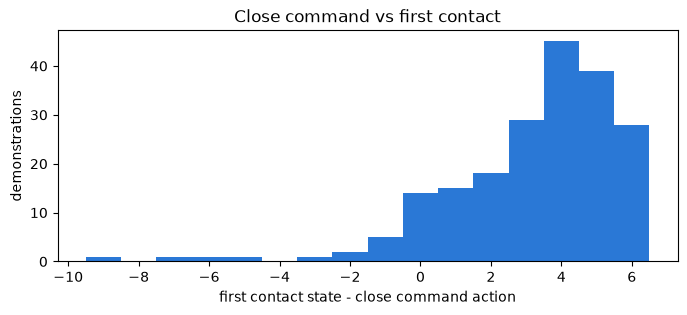

contact after the close command: 87 %, at the same index: 7 %, before: 6 %


In [36]:
print("gripper switches per demo:", dict(zip(*np.unique([CMD[d]["switches"] for d in DEMOS], return_counts=True))))
lag = np.array([CMD[d]["first_contact"] - CMD[d]["switch"] for d in DEMOS])

fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(lag, bins=range(lag.min(), lag.max() + 2), color="#2a78d6", align="left")
ax.set(xlabel="first contact state - close command action", ylabel="demonstrations", title="Close command vs first contact")
plt.show()
print(f"contact after the close command: {np.mean(lag > 0) * 100:.0f} %, at the same index: {np.mean(lag == 0) * 100:.0f} %, before: {np.mean(lag < 0) * 100:.0f} %")

- Every demonstration has exactly **one** switch: open for the whole approach, then closed until the end. So the whole gripper command is one number: the action index of the switch.
- In most demonstrations, the close command comes a few actions before the first contact: the fingers take time to close. In a few, a finger touches the cube **before** the close command, while the gripper is still open.

For the fit: the Bézier curve gives only the pose. The gripper switch is kept separately, and the curve must put the gripper in the right pose at that action. Section 4.6 requires the same switch step as the replay.

## 5.6 A rough fit preview

How close can a smooth curve with $K$ segments come to the commands? The real fit is on the manifold, with $C^1$ knots and fixed endpoints, and is not built yet. This preview uses a simpler stand-in:
- position: a cubic least-squares spline in R³ with $K$ equal segments (`scipy.interpolate.make_lsq_spline`);
- orientation: the same spline on the rotation vector of $R^{cmd\,\top}_0 R^{cmd}_t$. This is safe here only because these angles stay well below π (Part 1).

This spline is $C^2$, smoother than the plan's $C^1$ curve, and it has free endpoints. So it gives only a rough estimate of the fit error, not the real value.

In [37]:
from scipy.interpolate import make_lsq_spline


def preview_fit(d, K):
    '''Fit cubic least-squares splines with K equal segments to one demo's commands.

    Args:
        d (dict): One entry of CMD.
        K (int): Number of segments.

    Returns:
        np.ndarray: Position (m) and rotation (rad) residual per command, shape (N, 2).
    '''
    u = np.arange(d["N"]) / (d["N"] - 1)
    knots = np.r_[[0.0] * 4, np.linspace(0, 1, K + 1)[1:-1], [1.0] * 4]
    rotvec = Rotation.from_matrix(d["cmd_rot"][0].T @ d["cmd_rot"]).as_rotvec()
    pos_fit = make_lsq_spline(u, d["cmd_pos"], knots, k=3)(u)
    rot_fit = Rotation.from_rotvec(make_lsq_spline(u, rotvec, knots, k=3)(u)).as_matrix()
    return np.stack([np.linalg.norm(pos_fit - d["cmd_pos"], axis=1), geodesic(d["cmd_rot"][0] @ rot_fit, d["cmd_rot"])], axis=1)


Ks = (3, 5, 8, 10, 15)
res = {K: [preview_fit(CMD[d], K) for d in DEMOS] for K in Ks}
print(f"{'K':>3s}{'pos median':>12s}{'pos max (median demo)':>24s}{'pos max (worst)':>18s}{'rot max (median demo)':>24s}{'rot max (worst)':>18s}")
for K in Ks:
    pmed = np.median(np.concatenate([r[:, 0] for r in res[K]])) * 1000
    pmax = np.array([r[:, 0].max() for r in res[K]]) * 1000
    rmax = np.degrees([r[:, 1].max() for r in res[K]])
    print(f"{K:3d}{pmed:10.1f} mm{np.median(pmax):21.1f} mm{pmax.max():15.1f} mm{np.median(rmax):21.2f} deg{rmax.max():14.1f} deg")

  K  pos median   pos max (median demo)   pos max (worst)   rot max (median demo)   rot max (worst)
  3       6.6 mm                 17.0 mm           42.0 mm                 0.86 deg          16.1 deg
  5       5.0 mm                 13.4 mm           38.4 mm                 0.61 deg          11.5 deg
  8       4.0 mm                 10.7 mm           36.8 mm                 0.45 deg          10.3 deg
 10       3.5 mm                  9.8 mm           39.1 mm                 0.39 deg           8.8 deg
 15       2.9 mm                  8.0 mm           39.5 mm                 0.28 deg           4.6 deg


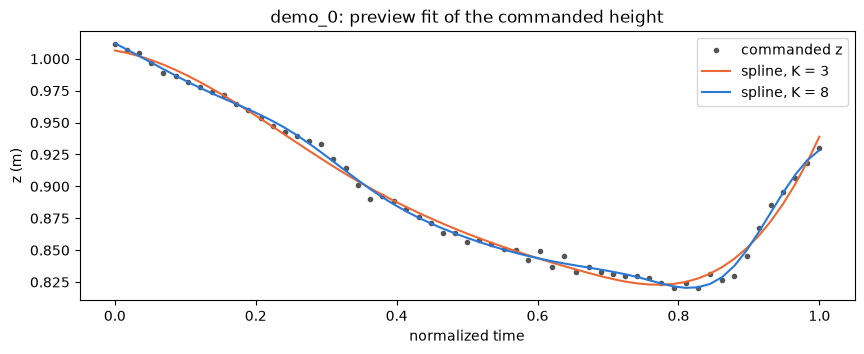

In [38]:
d = CMD["demo_0"]
u = np.arange(d["N"]) / (d["N"] - 1)
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(u, d["cmd_pos"][:, 2], "o", ms=3, color="#555555", label="commanded z")
for K, color in ((3, "#eb6834"), (8, "#2a78d6")):
    knots = np.r_[[0.0] * 4, np.linspace(0, 1, K + 1)[1:-1], [1.0] * 4]
    ax.plot(u, make_lsq_spline(u, d["cmd_pos"][:, 2], knots, k=3)(u), color=color, label=f"spline, K = {K}")
ax.set(xlabel="normalized time", ylabel="z (m)", title="demo_0: preview fit of the commanded height")
ax.legend()
plt.show()

What the preview shows:
- The median error falls slowly as $K$ grows, to a few millimetres. The spline passes through the middle of the jitter.
- The **largest** position error in a typical demonstration stays near 1 cm (8 mm with 15 segments). The worst demonstrations have about 4 cm. These are single large jumps in the commands (section 5.2), which no smooth curve can follow.

- For orientation, the typical largest error is below 1° for every $K$ tested. The worst demonstrations are again single large jumps.

So the level-1 position limit of section 4.6 (command difference ≤ 3 mm) **cannot be met** by this smooth curve, for most demonstrations. That limit was a proposal. The data now says that it measures the jitter, not the quality of the fit. What matters is the effect on the robot, after the controller has smoothed the commands: level 2 and above, measured by evaluation. Section 4.6 now reports the command difference without a limit.

## 5.7 Decisions from Part 5

Two findings of this part change the fitting plan. This section gives the evidence for each one, and the decision.

### A knot at the gripper close command

Section 5.1 showed that the grasp falls at a different fraction of normalized time in each demonstration. The next cell splits each demonstration at the close command $s$ (the action where `gripper_cmd` switches), and measures both parts.

In [39]:
pre = np.array([CMD[d]["switch"] for d in DEMOS])
post = np.array([CMD[d]["N"] - 1 - CMD[d]["switch"] for d in DEMOS])
turn = np.array([int(np.argmin(CMD[d]["cmd_pos"][:, 2])) - CMD[d]["switch"] for d in DEMOS])

print(f"before the close command: {pre.min()} to {pre.max()} actions (median {np.median(pre):.0f})")
print(f"after the close command:  {post.min()} to {post.max()} actions (median {np.median(post):.0f})")
print(f"correlation of the two lengths: {np.corrcoef(pre, post)[0, 1]:.2f}")
print("lowest commanded height, actions after the close command:", dict(zip(*np.unique(turn, return_counts=True))))

before the close command: 20 to 49 actions (median 33)
after the close command:  11 to 19 actions (median 13)
correlation of the two lengths: -0.09
lowest commanded height, actions after the close command: {np.int64(-6): np.int64(1), np.int64(-5): np.int64(1), np.int64(-4): np.int64(2), np.int64(-3): np.int64(1), np.int64(-2): np.int64(13), np.int64(-1): np.int64(12), np.int64(0): np.int64(15), np.int64(1): np.int64(37), np.int64(2): np.int64(60), np.int64(3): np.int64(33), np.int64(4): np.int64(13), np.int64(5): np.int64(5), np.int64(6): np.int64(3), np.int64(7): np.int64(3), np.int64(9): np.int64(1)}


- Almost all of the length difference between demonstrations is in the approach. The part after the close command is nearly the same length in every demonstration, and the two lengths are not correlated.
- So dividing the whole demonstration by $N$ stretches or squeezes the grasp and lift according to how long the **approach** took. This is an effect of the normalization, not of the motion.
- The lowest commanded height, where the path turns from down to up, is 0 to 3 actions after the close command in most demonstrations. The sharpest turn of the path is tied to the switch.

**Decision 1.** Put one knot at the close command $s$. Use $K_1$ equal segments before it and $K_2$ after it:
- The part before covers commands $0$ to $s$, with duration $T_{pre} = 0.05\,s$ seconds. The part after covers commands $s$ to $N-1$, with $T_{post} = 0.05\,(N-1-s)$ seconds. Inside each part, time is linear in seconds.
- The pose at the knot is a free control point at a fixed time. It is not pinned.
- The model predicts $T_{pre}$ and $T_{post}$ as continuous values. At deployment, the gripper closes at action round($T_{pre}$ / 0.05 s), because it can switch only at an action boundary.
- A segment before the knot and a segment after it usually have different durations. For the velocity to be continuous in seconds at the knot, the control handles on the two sides must be scaled by the ratio of these durations. So the decoder takes the durations as input.
- The close command is part of the commanded data, so the knot is exact. The first contact is not used: it is a simulation result that a policy cannot output.

### The fixed start point

Section 5.4 showed that command 0 is an outlier in some demonstrations. The first explanation tested was the stale controller start of Part 2 (hypothesis H19): at $t = 0$ the recording's controller used a nominal pose, not the real start pose. The next cell reads that nominal pose for each demonstration, and compares it with the jump.

In [40]:
from bezier_rfm.datasets.robomimic import arm_controller, load_demo_model

jump = np.array([geodesic(CMD[d]["cmd_rot"][:1], CMD[d]["cmd_rot"][1:2])[0] for d in DEMOS])
offset = []
with h5py.File(SOURCE_PATH, "r") as src:
    env = make_env(json.loads(meta["env_args"]), src["data/demo_0/obs"].keys())
    for d in DEMOS:
        load_demo_model(env, src[f"data/{d}"])
        # Before the first step, the controller still holds the nominal pose that the stale start uses.
        nominal = np.array(arm_controller(env).ref_ori_mat)
        offset.append(geodesic(nominal[None], CMD[d]["ach_rot"][:1])[0])
offset = np.array(offset)

big = jump > np.radians(5)
print(f"nominal vs true start orientation: median {np.degrees(np.median(offset)):.1f} deg, max {np.degrees(offset.max()):.1f} deg")
print(f"correlation of the jump with this offset: {np.corrcoef(jump, offset)[0, 1]:.2f}")
print(f"robot rotation in the first step, demos with a jump above 5 deg: median {np.degrees(np.median([geodesic(CMD[d]['ach_rot'][:1], CMD[d]['ach_rot'][1:2])[0] for d in np.array(DEMOS)[big]])):.1f} deg")


============= Initialized Observation Utils with Obs Spec =============

using obs modality: low_dim with keys: ['robot0_gripper_qvel', 'robot0_eef_pos', 'robot0_joint_pos_sin', 'object', 'robot0_joint_vel', 'robot0_eef_quat_site', 'robot0_eef_quat', 'robot0_joint_pos', 'robot0_joint_pos_cos', 'robot0_gripper_qpos']
using obs modality: rgb with keys: []


Created environment with name Lift
Action size is 7


nominal vs true start orientation: median 2.5 deg, max 7.3 deg
correlation of the jump with this offset: 0.05
robot rotation in the first step, demos with a jump above 5 deg: median 1.2 deg


The nominal pose is close to the true start, and the jump does not depend on the offset. So the stale start does **not** explain the jump. **H19 is rejected.**

The second explanation (hypothesis H20) is in the raw delta actions of the original dataset: the input of the 3D mouse at $t = 0$.

In [41]:
with h5py.File(SOURCE_PATH, "r") as src:
    for d in ("demo_105", "demo_131", "demo_0"):
        print(f"{d}: rotation input at t = 0 to 3:\n{np.round(src[f'data/{d}/actions'][:4, 3:6], 3)}")
    raw = {d: src[f"data/{d}/actions"][:] for d in DEMOS}

# Size of the change of the rotation input from one action to the next, in degrees (input 1 = 0.5 rad).
change = {d: np.degrees(np.linalg.norm(np.diff(raw[d][:, 3:6], axis=0), axis=1) * 0.5) for d in DEMOS}
spikes = sum(change[d][0] > np.percentile(change[d][1:], 99) for d in DEMOS)
pos0 = np.array([np.linalg.norm(raw[d][0, :3]) for d in DEMOS]) * 50
pos1 = np.array([np.linalg.norm(raw[d][1, :3]) for d in DEMOS]) * 50
print(f"demos where the rotation input change from t = 0 to 1 is above the demo's own 99th percentile of later changes: {spikes}")
print(f"position input size (mm): t = 0 median {np.median(pos0):.1f}, t = 1 median {np.median(pos1):.1f}")

demo_105: rotation input at t = 0 to 3:
[[ 0.017 -1.     0.011]
 [ 0.003  0.108 -0.011]
 [ 0.001  0.122 -0.005]
 [ 0.002  0.112 -0.002]]
demo_131: rotation input at t = 0 to 3:
[[ 0.033  0.157  0.478]
 [-0.016  0.084 -0.052]
 [-0.022  0.076 -0.063]
 [-0.028  0.067 -0.059]]
demo_0: rotation input at t = 0 to 3:
[[ 0.004  0.148  0.014]
 [ 0.004  0.138  0.005]
 [ 0.007  0.129 -0.008]
 [ 0.008  0.123 -0.025]]
demos where the rotation input change from t = 0 to 1 is above the demo's own 99th percentile of later changes: 38
position input size (mm): t = 0 median 0.0, t = 1 median 18.9


- In the outlier demonstrations, the rotation input at $t = 0$ is a single **spike**: in `demo_105`, it is at the device limit (−1, which is 28.6°), and the next inputs are near 0.1. In `demo_0`, the first input matches the next ones.
- In about 1 in 5 demonstrations, the first change of the rotation input is larger than the demo's 99th percentile of later changes. The position input has no spike: at $t = 0$ it is zero or small.
- The robot hardly follows the spike: the goal changes back after one step of 0.05 s, and the lag is about 0.16 s.

So the spike is an artefact of the first reading of the device, not something the demonstrator meant. **H20 is confirmed.**

**Decision 2.** Fix the curve's start $q_0$ to the **actual start pose**, not to command 0:
- At deployment, the start pose is known exactly from the observation. So the curve always starts at the robot, and the model does not have to generate $q_0$ or learn the spikes.
- The cost: in normal demonstrations, command 0 already leads the start pose by a few degrees. With $q_0$ at the start pose, the curve begins with no lead, so the robot starts about one action later. That is small against the lag of about 3 actions.
- The stored dataset `low_dim_abs.hdf5` stays unchanged. It is the faithful conversion of the demonstrations, and the baseline depends on it. A new derived file has action 0 replaced by the start pose. The new reference replay for the pass rule is made from it (hypothesis H21).

## Part 5 summary

- Demonstrations have 36 to 64 actions. With equal knots, one segment covers a different number of actions in each demonstration.
- The grasp happens between about 55 % and 80 % of normalized time. The grasp and lift together are about one segment for $K = 5$.
- A typical command step is about 1 cm and 0.5°. The command never stands still, and about 10 % of the original inputs are at the device limit.
- The commanded path is about 9 times more jagged than the achieved path. The controller filters the jitter out.
- Command 0 is a rotation or position outlier in about 1 in 10 demonstrations, because of a spike in the first rotation input. The fit fixes its start to the actual start pose instead (section 5.7).
- The gripper is one switch per demonstration, kept separately from the curve.
- A rough spline preview cannot get within 3 mm of the commands everywhere, for any $K$ tested. Orientation is typically within 1°.
- Two decisions follow (section 5.7): a knot at the gripper close command with predicted part durations, and a fixed start at the actual start pose. The fit limit must be judged on the robot's motion, not on the commands.

**Common mistake:** judging a fit by how closely it follows the commands. The commands contain jitter that the robot never follows. A curve that follows the jitter is not better for the robot; it may only be harder to learn.

## Exercise 5

Use the `CMD` dictionary and `preview_fit` from this part.

1. For $K = 5$, find in which segment (1 to 5) the gripper close command falls in each demonstration. Make a count per segment. In how many demonstrations is the close command within one action of a knot?
2. For `demo_105`, print the rotation step $d(R^{cmd}_t, R^{cmd}_{t+1})$ for $t = 0$ to 4, and the demo's median rotation step. Then use `preview_fit` with $K = 5$ and print the rotation residual at the first five commands.
3. For $K = 8$, find for each demonstration the **phase** where the position residual is largest. Make a count per phase. Use the `phases` entry of `CMD`.
4. In two or three sentences: which $K$ would you start the real fit with, and would you fix the curve's start to command 0? Give a reason from this part for each.

Write your answer in the next cell.

In [42]:
# Your answer for Exercise 5.

---
# Part 6. Evaluating new commands

Parts 1 to 5 used only the demonstrator's own commands. Part 6 runs **new** command sequences through the same evaluation, and compares them with a reference. The first new sequence is not a Bézier fit. It is the reference itself.

## 6.1 The q₀-start reference (H21)

Section 5.7 decided that the fit starts at the actual start pose. So a candidate must be compared with a replay that also starts there. `scripts/make_q0start_actions.py` writes `low_dim_abs_q0start.hdf5`: a copy of `low_dim_abs.hdf5` with `actions[0, :6]` set to the grip-site pose at state 0. All other actions are unchanged. `scripts/add_replay_traces.py` replays it, and adds the group `replay_q0start` to the traces file.

**Hypothesis H21.** Replacing action 0 with the start pose changes the replay only in a short start transient. The criteria, agreed before the run:

| # | Check | Pass if |
| --- | --- | --- |
| 1 | command fidelity | action 0 ≤ 1e-12 m and rad; every other action exactly 0 |
| 2 | time, shapes, finite values, rotations | the H18 limits |
| 3 | lift outcome, demo by demo, vs `replay_absolute` | 199 of 200 or better; every changed demo inspected |
| 4 | gripper position difference vs `replay_absolute` | median over demos below 0.1 mm for every $t \ge 10$ |

In [43]:
import sys

sys.path.insert(0, str(ROOT / "scripts"))
from validate_diagnostics import ORTHO_TOL, TIME_TOL, check_completeness, check_time

Q0 = {}
with h5py.File(TRACES_PATH, "r") as f:
    for name in DEMOS:
        Q0[name] = {k: read_trace(f[f"{name}/{k}"])[0] for k in ("recorded", "replay_absolute", "replay_q0start")}
    print("actions file SHA-256:", read_trace(f["demo_0/replay_q0start"])[1]["actions_sha256"])

fid0 = max(command_fidelity(Q0[d]["replay_q0start"])[0].max() for d in DEMOS)
fid_rest = max(command_fidelity(Q0[d]["replay_q0start"])[1:].max() for d in DEMOS)
times = [check_time(Q0[d]["replay_q0start"], "replay") for d in DEMOS]
complete = [check_completeness(Q0[d]["replay_q0start"]) for d in DEMOS]
time_err = max(max(t["interval"], t["start_times"], t["state_times"]) for t in times)
print(f"1. fidelity: action 0 max {fid0:.1e}, other actions max {fid_rest:.1e}")
print(f"2. time error max {time_err:.1e} s (limit {TIME_TOL:g}), all states valid: {all(t['valid_states'] == t['expected_valid'] for t in times)}, "
      f"problems: {sum(len(c['problems']) for c in complete)}, orthonormality max {max(c['ortho'] for c in complete):.1e} (limit {ORTHO_TOL:g})")

lift_abs = np.array([Q0[d]["replay_absolute"]["success"][-1] for d in DEMOS])
lift_q0 = np.array([Q0[d]["replay_q0start"]["success"][-1] for d in DEMOS])
height_diff = np.array([Q0[d]["replay_q0start"]["cube_height"][-1] - Q0[d]["replay_absolute"]["cube_height"][-1] for d in DEMOS]) * 1000
print(f"3. lifted: replay_absolute {lift_abs.sum()}, replay_q0start {lift_q0.sum()}, changed: {[d for d, a, b in zip(DEMOS, lift_abs, lift_q0) if a != b]}")
print(f"   final cube height difference: median {np.median(height_diff):.3f} mm, largest {np.abs(height_diff).max():.2f} mm ({DEMOS[int(np.argmax(np.abs(height_diff)))]})")

actions file SHA-256: 27d1179b3719e442eeae85db15094c5c32b59c02b246dc63e70dc4fb58dad9e6
1. fidelity: action 0 max 0.0e+00, other actions max 0.0e+00
2. time error max 1.3e-13 s (limit 1e-09), all states valid: True, problems: 0, orthonormality max 6.6e-15 (limit 1e-09)
3. lifted: replay_absolute 199, replay_q0start 199, changed: []
   final cube height difference: median 0.003 mm, largest 2.42 mm (demo_185)


Criteria 1 to 3 pass. The fidelity is exactly zero even at action 0: the start rotation goes through one rotation-vector conversion, and here it comes back bit for bit. The same demonstrations lift the cube, and the final heights differ by a few millimetres at most.

The next cell tests criterion 4. It also shows the largest arm-joint difference, to explain the shape of the curve.

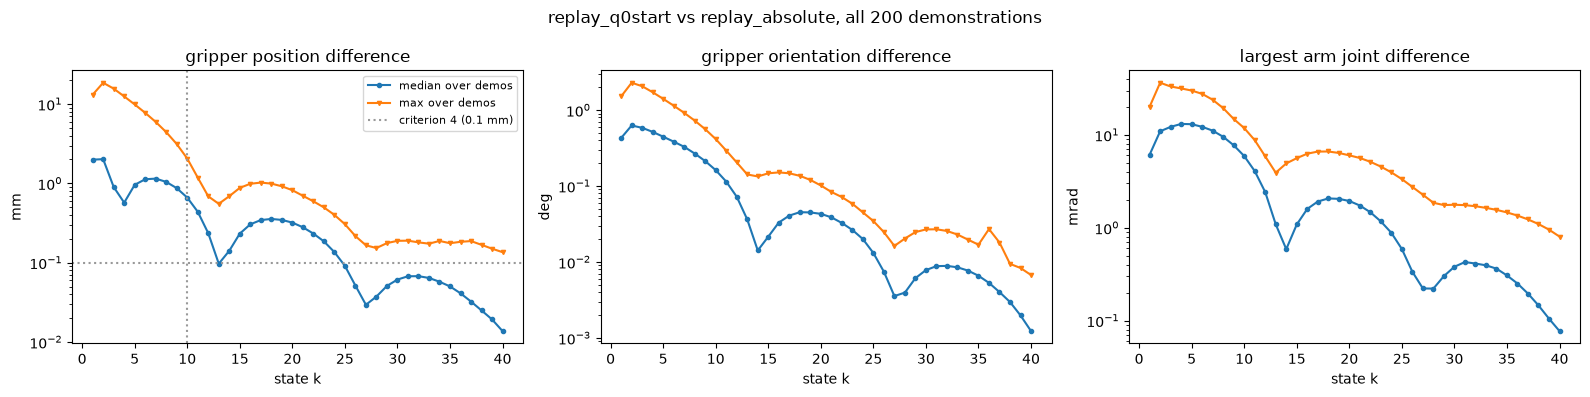

4. states k >= 10 with median >= 0.1 mm: [10, 11, 12, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]
   largest median after k = 10: 0.661 mm at k = 10; largest single value after k = 10: 2.06 mm
   median below 0.1 mm for every k >= 25


In [44]:
T_MAX = 40
diff = {key: np.full((len(DEMOS), T_MAX + 1), np.nan) for key in ("pos", "rot", "joint")}
for i, d in enumerate(DEMOS):
    a, q = Q0[d]["replay_absolute"], Q0[d]["replay_q0start"]
    k = min(T_MAX + 1, len(a["valid"]))
    diff["pos"][i, :k] = np.linalg.norm(q["ach_pos"][:k] - a["ach_pos"][:k], axis=1) * 1000
    diff["rot"][i, :k] = np.degrees(geodesic(q["ach_rot"][:k], a["ach_rot"][:k]))
    # state[1:8] are the seven arm joint angles.
    diff["joint"][i, :k] = np.abs(q["state"][:k, 1:8] - a["state"][:k, 1:8]).max(axis=1) * 1000

ks = np.arange(1, T_MAX + 1)
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, key, unit in zip(axes, ("pos", "rot", "joint"), ("mm", "deg", "mrad")):
    ax.semilogy(ks, np.nanmedian(diff[key][:, 1:], axis=0), "o-", ms=3, label="median over demos")
    ax.semilogy(ks, np.nanmax(diff[key][:, 1:], axis=0), "v-", ms=3, label="max over demos")
    ax.set(xlabel="state k", ylabel=unit)
axes[0].axhline(0.1, color="#999999", ls=":", label="criterion 4 (0.1 mm)")
axes[0].axvline(10, color="#999999", ls=":")
axes[0].set_title("gripper position difference")
axes[1].set_title("gripper orientation difference")
axes[2].set_title("largest arm joint difference")
axes[0].legend(fontsize=8)
fig.suptitle("replay_q0start vs replay_absolute, all 200 demonstrations")
fig.tight_layout()
plt.show()

med = np.nanmedian(diff["pos"], axis=0)
above = [k for k in range(10, T_MAX + 1) if med[k] >= 0.1]
print(f"4. states k >= 10 with median >= 0.1 mm: {above}")
print(f"   largest median after k = 10: {med[10:].max():.3f} mm at k = {10 + int(np.argmax(med[10:]))}; largest single value after k = 10: {np.nanmax(diff['pos'][:, 10:]):.2f} mm")
print(f"   median below 0.1 mm for every k >= {max(above) + 1}")

**Criterion 4 fails as written.** At $k = 10$ the first decay is not finished (median 0.66 mm). The median falls below 0.1 mm at $k = 14$, rises again to about 0.36 mm at $k = 18$, and stays below 0.1 mm only from $k = 25$.

The joint panel shows why. The arm-joint difference does not decay smoothly. It decays as a **damped oscillation**: a large lobe around $k = 4$, a second lobe about 6 times smaller around $k = 18$, and a third around $k = 31$. The controller is critically damped for the gripper pose, but the joints of the arm still swing slowly while the gripper converges. The gripper difference follows these lobes. The criterion assumed a smooth decay, as in section 4.4, so it did not allow for the second lobe.

How large is the effect?
- From $k = 12$ on, the median is at most about 0.36 mm, and the largest value in any demonstration about 1 mm. That is small against the 1.7 cm clearance at the cube.
- In the grasp and lift phases, the gripper difference has a median of about 0.02 mm, and the outcome does not change.
- The demos without the input spike show the same curve. So it is caused mainly by removing the lead of a few degrees that command 0 has in every demonstration, not by the spike.

`demo_105` has the largest spike. The next cell draws its pose figure with both replays. The saved figures are in `docs/diagnostics/figures/q0start/`.

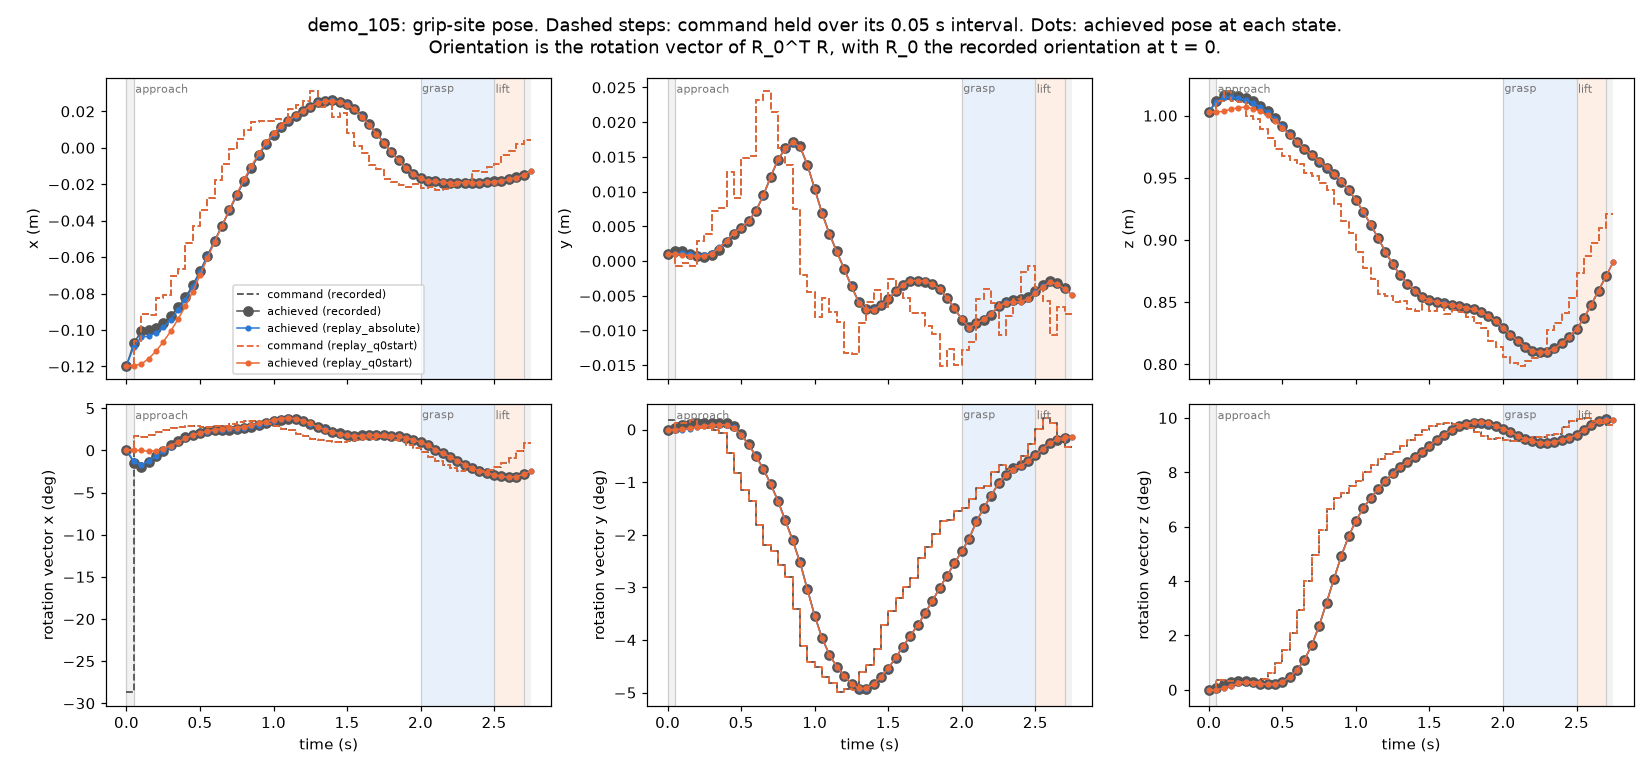

In [45]:
from IPython.display import Image

from bezier_rfm.eval import lift_plots

# lift_plots selects the Agg backend when it is imported; switch back so later cells still show plots inline.
plt.switch_backend("module://matplotlib_inline.backend_inline")
paths = lift_plots.plot_diagnostics(ROOT / "docs/diagnostics/figures/q0start", "demo_105", Q0["demo_105"]["recorded"], {"replay_absolute": Q0["demo_105"]["replay_absolute"], "replay_q0start": Q0["demo_105"]["replay_q0start"]})
Image(filename=str(paths[0]), width=1100)

In the orientation panels, the stored command (grey dashes), which `replay_absolute` also uses, starts with the spike at $t = 0$. The command of `replay_q0start` (orange dashes) starts at the robot's own orientation. After $t = 0$ the two commands are the same. In the x panel, the spike also pushes the `replay_absolute` gripper forward in the first step, while `replay_q0start` starts more slowly. The achieved poses meet again within about 10 actions (0.5 s).

**Revised criterion 4.** The original criterion assumed a smooth decay. It was revised after the run, with the user's approval, to describe the oscillation that the data shows. The revised criterion has two parts:
- the median over demos is below 0.1 mm for every $k \ge 25$, after the second lobe;
- the largest value in any demo is at most 3 mm for every $k \ge 10$. This is the gripper limit of the pass rule (section 4.6), so after the start, the new reference stays inside the tolerance that a candidate gets.

In [46]:
med_ok = bool((np.nanmedian(diff["pos"][:, 25:], axis=0) < 0.1).all())
max_after = np.nanmax(diff["pos"][:, 10:])
print(f"revised 4a: median < 0.1 mm for every k >= 25: {med_ok}")
print(f"revised 4b: largest value for k >= 10 is {max_after:.2f} mm (limit 3 mm): {max_after <= 3.0}")

revised 4a: median < 0.1 mm for every k >= 25: True
revised 4b: largest value for k >= 10 is 2.06 mm (limit 3 mm): True


**Result of H21: confirmed, with the revised criterion 4.** Criteria 1 to 3 pass as written. The original criterion 4 failed, because the difference decays with a second, smaller lobe. The revised criterion 4 passes. The outcome is unchanged in every demonstration.

**Decision.** `replay_q0start` is now the reference for Bézier candidates (section 4.6). Because a candidate also starts at the start pose, the start transient seen here does not appear in candidate comparisons.